# KAMP 전력사용량 예측 모델링 — 정리본

이 노트북은 기존 `KAMP_modeling_2_6.ipynb`의 흐름을 정리한 버전입니다.

- 기존 Baseline XGBoost 모델
- Baseline 오차 분석
- 정확히 4개의 추가 Feature 생성
  - `lag_1_power`
  - `lag_4_power`
  - `production_change`
  - `operation_state`
- Feature4 XGBoost 재학습 및 Baseline 비교
- Persistence Baseline 비교
- TimeSeriesSplit 검증
- Feature4 데이터 및 예측결과 저장

> **중요:** 모델 파라미터와 시간순 8:2 분할 방식은 기존 코드와 동일하게 유지했습니다.  
> `operation_state`의 One-Hot Encoding은 **모델 입력을 만들 때만 임시로 수행**하며, 저장용 데이터에는 새 Feature가 정확히 4개만 추가됩니다.


In [1]:
# ============================================================
# #0. 환경 설정 / 라이브러리 / 한글 폰트
# ============================================================

!apt-get -qq update
!apt-get -qq install fonts-nanum

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.font_manager as fm

from google.colab import files
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import TimeSeriesSplit

# 한글 폰트 적용
fm._load_fontmanager(try_read_cache=False)

nanum_fonts = [
    font for font in fm.fontManager.ttflist
    if 'NanumGothic' in font.name
]

if len(nanum_fonts) == 0:
    raise RuntimeError("NanumGothic 폰트를 찾지 못했습니다.")

plt.rcParams['font.family'] = nanum_fonts[0].name
plt.rcParams['axes.unicode_minus'] = False


# ------------------------------------------------------------
# 공통 함수
# ------------------------------------------------------------

def make_xgb_model():
    # 현재 프로젝트에서 사용한 XGBoost 설정을 그대로 반환
    return XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective='reg:squarederror'
    )


def regression_metrics(y_true, y_pred):
    # MAE, RMSE, R² 계산
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

print("환경 설정 완료")
print("적용 폰트:", plt.rcParams['font.family'])


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
환경 설정 완료
적용 폰트: ['NanumGothicCoding']


In [2]:
# ============================================================
# #1. 데이터 불러오기
# ============================================================

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

df_raw = pd.read_csv(file_name)

print("불러온 파일:", file_name)
print("데이터 크기:", df_raw.shape)
print("\n컬럼:")
print(df_raw.columns.tolist())

df_raw.head()


Saving Power15MinClean_NoDatetime.csv to Power15MinClean_NoDatetime.csv
불러온 파일: Power15MinClean_NoDatetime.csv
데이터 크기: (24672, 17)

컬럼:
['날짜', '시간', '분', '전력사용량', '평균', '생산량', '기온', '풍속', '습도', '강수량', '전기요금(계절)', 'day', 'd', 'm', '공장인원', '인건비', '이상구간여부']


,날짜,시간,분,전력사용량,평균,생산량,기온,풍속,습도,강수량,전기요금(계절),day,d,m,공장인원,인건비,이상구간여부
0,20210101,0,15,62,61,0,-3.2,2.4,71,0.0,109.8,5,1,1,0.0,1.5,0
1,20210101,0,30,61,61,0,-3.2,2.4,71,0.0,109.8,5,1,1,0.0,1.5,0
2,20210101,0,45,61,61,0,-3.2,2.4,71,0.0,109.8,5,1,1,0.0,1.5,0
3,20210101,0,60,61,61,0,-3.2,2.4,71,0.0,109.8,5,1,1,0.0,1.5,0
4,20210101,1,15,96,105,0,-4.5,1.5,77,0.0,109.8,5,1,1,0.0,1.5,0


## 1. Baseline 모델

Baseline에서는 현재 전력사용량을 직접적으로 이용하는 `평균`, 사후적으로 생성되었을 가능성이 있는 `이상구간여부`를 입력변수에서 제외합니다.

시간순으로 앞 80%를 Train, 뒤 20%를 Test로 사용합니다. 데이터는 섞지 않습니다.


In [3]:
# ============================================================
# #2. Baseline 데이터 준비
# ============================================================

df_base = df_raw.copy()

df_base['날짜_dt'] = pd.to_datetime(
    df_base['날짜'].astype(str),
    format='%Y%m%d'
)

df_base = (
    df_base
    .sort_values(['날짜_dt', '시간', '분'])
    .reset_index(drop=True)
)

baseline_features = [
    '시간',
    '분',
    '생산량',
    '기온',
    '풍속',
    '습도',
    '강수량',
    '전기요금(계절)',
    'day',
    'd',
    'm',
    '공장인원',
    '인건비'
]

target = '전력사용량'

print("Baseline Feature 수:", len(baseline_features))
print(baseline_features)


Baseline Feature 수: 13
['시간', '분', '생산량', '기온', '풍속', '습도', '강수량', '전기요금(계절)', 'day', 'd', 'm', '공장인원', '인건비']


In [4]:
# ============================================================
# #3. Baseline 시간순 Train / Test 8:2 분할 및 학습
# ============================================================

split_idx_base = int(len(df_base) * 0.8)

train_base = df_base.iloc[:split_idx_base].copy()
test_base = df_base.iloc[split_idx_base:].copy()

X_train_base0 = train_base[baseline_features]
X_test_base0 = test_base[baseline_features]

y_train_base0 = train_base[target]
y_test_base0 = test_base[target]

baseline_model_initial = make_xgb_model()
baseline_model_initial.fit(X_train_base0, y_train_base0)

baseline_train_pred0 = baseline_model_initial.predict(X_train_base0)
baseline_test_pred0 = baseline_model_initial.predict(X_test_base0)

baseline_train_metrics0 = regression_metrics(
    y_train_base0,
    baseline_train_pred0
)

baseline_test_metrics0 = regression_metrics(
    y_test_base0,
    baseline_test_pred0
)

print("Train 데이터:", X_train_base0.shape)
print("Test 데이터 :", X_test_base0.shape)

print("\nTrain 기간:",
      train_base['날짜_dt'].min(),
      "~",
      train_base['날짜_dt'].max())

print("Test 기간 :",
      test_base['날짜_dt'].min(),
      "~",
      test_base['날짜_dt'].max())

print("\n========== Baseline Train 성능 ==========")
print(f"MAE  : {baseline_train_metrics0['MAE']:.4f}")
print(f"RMSE : {baseline_train_metrics0['RMSE']:.4f}")
print(f"R²   : {baseline_train_metrics0['R2']:.4f}")

print("\n========== Baseline Test 성능 ==========")
print(f"MAE  : {baseline_test_metrics0['MAE']:.4f}")
print(f"RMSE : {baseline_test_metrics0['RMSE']:.4f}")
print(f"R²   : {baseline_test_metrics0['R2']:.4f}")

print("\n========== Train / Test 차이 ==========")
print(f"MAE 차이  : {baseline_test_metrics0['MAE'] - baseline_train_metrics0['MAE']:.4f}")
print(f"RMSE 차이 : {baseline_test_metrics0['RMSE'] - baseline_train_metrics0['RMSE']:.4f}")
print(f"R² 차이   : {baseline_train_metrics0['R2'] - baseline_test_metrics0['R2']:.4f}")


Train 데이터: (19737, 13)
Test 데이터 : (4935, 13)

Train 기간: 2021-01-01 00:00:00 ~ 2021-07-25 00:00:00
Test 기간 : 2021-07-25 00:00:00 ~ 2021-09-14 00:00:00

========== Baseline Train 성능 ==========
MAE  : 6.9069
RMSE : 10.0215
R²   : 0.9690

========== Baseline Test 성능 ==========
MAE  : 17.5383
RMSE : 29.9633
R²   : 0.7670

========== Train / Test 차이 ==========
MAE 차이  : 10.6314
RMSE 차이 : 19.9418
R² 차이   : 0.2020


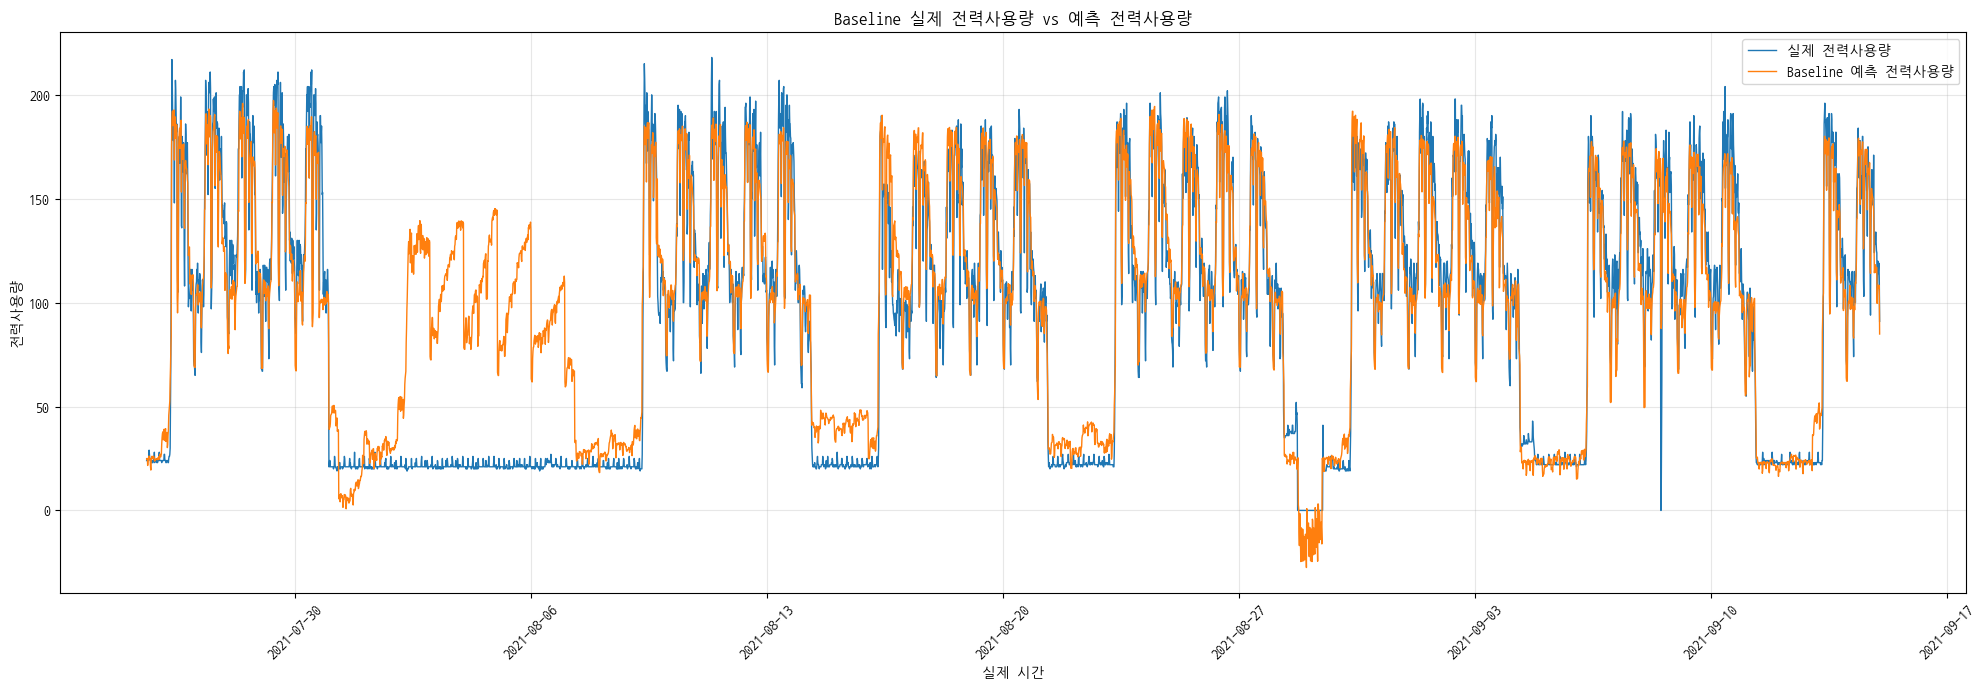

In [5]:
# ============================================================
# #4. Baseline 실제값 vs 예측값
# ============================================================

baseline_test_time = (
    test_base['날짜_dt'].dt.normalize()
    + pd.to_timedelta(test_base['시간'], unit='h')
    + pd.to_timedelta(test_base['분'], unit='m')
)

plt.figure(figsize=(20, 7))

plt.plot(
    baseline_test_time,
    y_test_base0.values,
    label='실제 전력사용량',
    linewidth=1
)

plt.plot(
    baseline_test_time,
    baseline_test_pred0,
    label='Baseline 예측 전력사용량',
    linewidth=1
)

plt.xlabel('실제 시간')
plt.ylabel('전력사용량')
plt.title('Baseline 실제 전력사용량 vs 예측 전력사용량')

plt.legend()
plt.grid(alpha=0.3)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 2. Baseline 오차 분석

Baseline 모델에서 절대오차 상위 5%를 추출하고, 어떤 조건에서 큰 오차가 나타나는지 확인합니다.


In [6]:
# ============================================================
# #5. Baseline 예측결과 및 대규모 오차 구간
# ============================================================

baseline_result = test_base.copy()

baseline_result['실제전력'] = y_test_base0.values
baseline_result['예측전력'] = baseline_test_pred0
baseline_result['오차'] = (
    baseline_result['실제전력']
    - baseline_result['예측전력']
)
baseline_result['절대오차'] = np.abs(
    baseline_result['오차']
)

baseline_error_threshold = (
    baseline_result['절대오차']
    .quantile(0.95)
)

baseline_large_error = baseline_result[
    baseline_result['절대오차']
    >= baseline_error_threshold
].copy()

print(f"절대오차 상위 5% 기준값: {baseline_error_threshold:.4f}")
print(f"전체 Test 데이터 수: {len(baseline_result)}")
print(f"대규모 오차 데이터 수: {len(baseline_large_error)}")

baseline_large_error[
    [
        '날짜_dt',
        '시간',
        '분',
        '생산량',
        '공장인원',
        '전력사용량',
        '예측전력',
        '절대오차'
    ]
].head(20)


절대오차 상위 5% 기준값: 83.7192
전체 Test 데이터 수: 4935
대규모 오차 데이터 수: 247


,날짜_dt,시간,분,생산량,공장인원,전력사용량,예측전력,절대오차
20231,2021-07-30,17,60,0,0.0,190,100.627785,89.372215
20232,2021-07-30,18,15,0,0.0,190,99.918465,90.081535
20480,2021-08-02,8,15,0,0.0,20,111.753326,91.753326
20481,2021-08-02,8,30,0,0.0,20,118.823380,98.823380
20482,2021-08-02,8,45,0,0.0,20,125.873978,105.873978
20483,2021-08-02,8,60,0,0.0,21,129.369675,108.369675
20484,2021-08-02,9,15,0,0.0,21,123.469635,102.469635
20485,2021-08-02,9,30,0,0.0,21,127.065994,106.065994
20486,2021-08-02,9,45,0,0.0,21,132.264938,111.264938
20487,2021-08-02,9,60,0,0.0,21,135.283463,114.283463


In [7]:
# ============================================================
# #6. 대규모 오차 구간 주요 조건 비교
# ============================================================

compare_variables = [
    '생산량',
    '시간',
    'day',
    'm',
    '공장인원',
    '인건비',
    '기온'
]

baseline_error_comparison = pd.DataFrame({
    '전체 Test 평균':
        baseline_result[compare_variables].mean(),

    '대규모 오차 평균':
        baseline_large_error[compare_variables].mean()
})

baseline_error_comparison['차이'] = (
    baseline_error_comparison['대규모 오차 평균']
    - baseline_error_comparison['전체 Test 평균']
)

print(baseline_error_comparison)

overall_abnormal_rate = (
    baseline_result['이상구간여부'].mean() * 100
)

large_error_abnormal_rate = (
    baseline_large_error['이상구간여부'].mean() * 100
)

print(
    f"\n전체 Test 이상구간 비율: "
    f"{overall_abnormal_rate:.2f}%"
)

print(
    f"대규모 오차 구간 이상구간 비율: "
    f"{large_error_abnormal_rate:.2f}%"
)


      전체 Test 평균  대규모 오차 평균          차이
생산량   512.614387   0.024291 -512.590096
시간     11.556231  16.340081    4.783850
day     3.926444   2.554656   -1.371788
m       8.147720   8.000000   -0.147720
공장인원    0.856386   0.000245   -0.856141
인건비     1.312462   1.244939   -0.067523
기온     24.834914  29.066397    4.231483

전체 Test 이상구간 비율: 1.38%
대규모 오차 구간 이상구간 비율: 0.00%


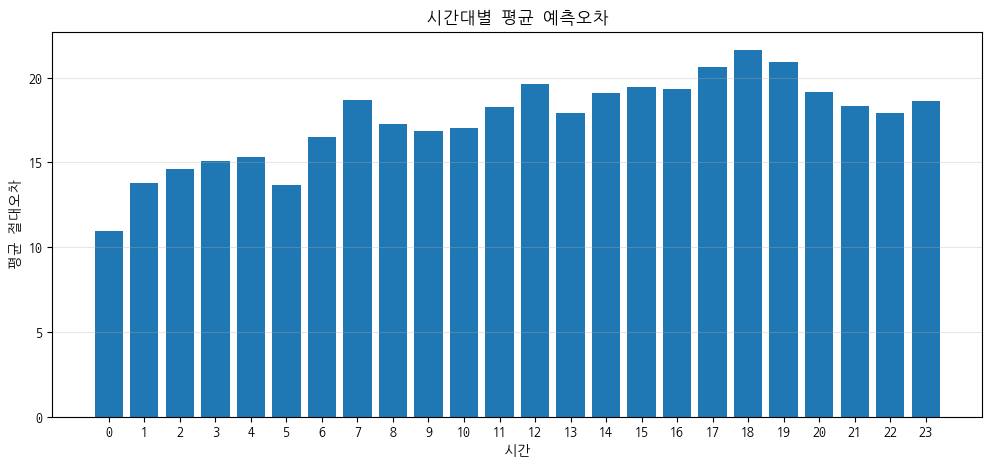

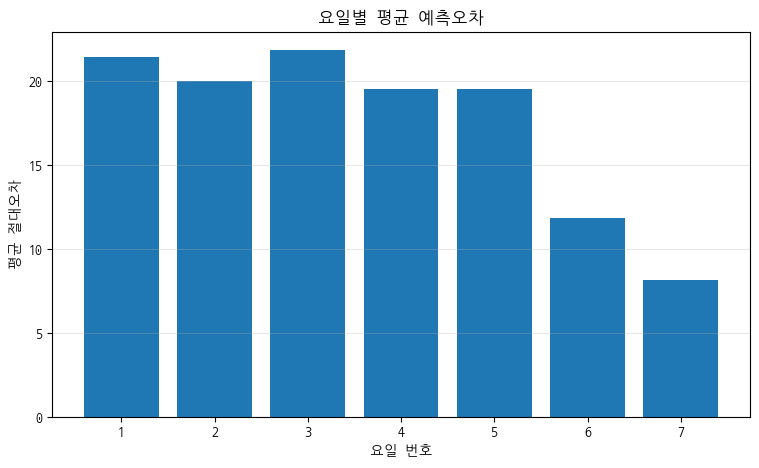

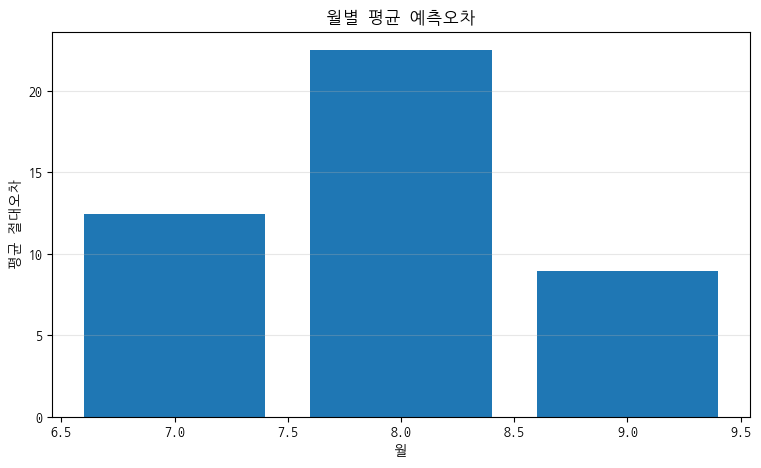

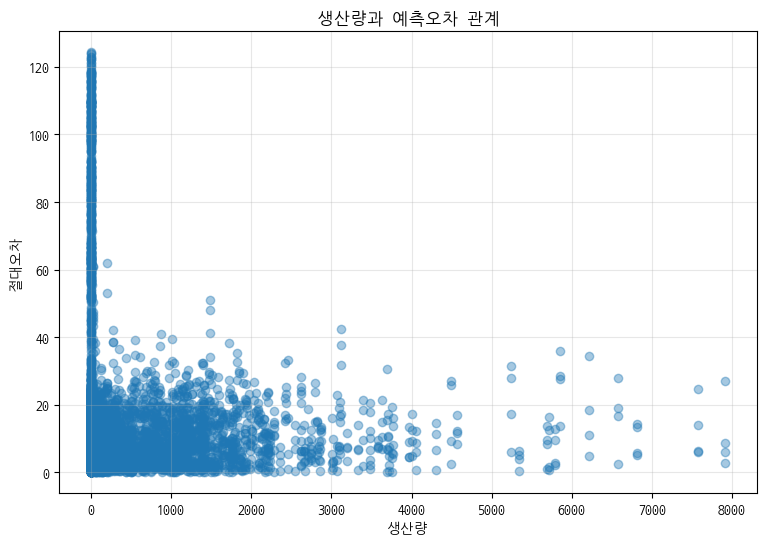

In [8]:
# ============================================================
# #7. Baseline 오차 패턴 시각화
# ============================================================

# 시간대별
hour_error = (
    baseline_result
    .groupby('시간')['절대오차']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.bar(hour_error['시간'], hour_error['절대오차'])
plt.xlabel('시간')
plt.ylabel('평균 절대오차')
plt.title('시간대별 평균 예측오차')
plt.xticks(range(24))
plt.grid(axis='y', alpha=0.3)
plt.show()


# 요일별
day_error = (
    baseline_result
    .groupby('day')['절대오차']
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.bar(day_error['day'], day_error['절대오차'])
plt.xlabel('요일 번호')
plt.ylabel('평균 절대오차')
plt.title('요일별 평균 예측오차')
plt.grid(axis='y', alpha=0.3)
plt.show()


# 월별
month_error = (
    baseline_result
    .groupby('m')['절대오차']
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.bar(month_error['m'], month_error['절대오차'])
plt.xlabel('월')
plt.ylabel('평균 절대오차')
plt.title('월별 평균 예측오차')
plt.grid(axis='y', alpha=0.3)
plt.show()


# 생산량과 오차
plt.figure(figsize=(9, 6))
plt.scatter(
    baseline_result['생산량'],
    baseline_result['절대오차'],
    alpha=0.4
)
plt.xlabel('생산량')
plt.ylabel('절대오차')
plt.title('생산량과 예측오차 관계')
plt.grid(alpha=0.3)
plt.show()


## 3. Feature Engineering

Baseline 오차 분석을 바탕으로 다음 **4개 Feature만** 추가합니다.

1. `lag_1_power`: 15분 전 전력사용량  
2. `lag_4_power`: 1시간 전 전력사용량  
3. `production_change`: 직전 15분 대비 생산량 변화  
4. `operation_state`: 생산 전환 상태

저장용 데이터프레임 `df_feature4`에는 기존 17개 컬럼 + 위 4개 컬럼 = **21개 컬럼만 존재**합니다.


In [9]:
# ============================================================
# #8. 정확히 4개 Feature 추가
# ============================================================

# 원본 CSV 기준으로 새 데이터프레임 생성
# → Baseline 과정에서 만든 임시 컬럼이 섞이지 않도록 함
df_feature4 = df_raw.copy()

original_columns = df_feature4.columns.tolist()

df_feature4 = (
    df_feature4
    .sort_values(['날짜', '시간', '분'])
    .reset_index(drop=True)
)

# ① 15분 전 전력
df_feature4['lag_1_power'] = (
    df_feature4['전력사용량'].shift(1)
)

# ② 1시간 전 전력
# 15분 간격이므로 4행 전
df_feature4['lag_4_power'] = (
    df_feature4['전력사용량'].shift(4)
)

# 이전 생산량은 계산용 Series로만 사용
# 별도 컬럼으로 저장하지 않음
prev_production = (
    df_feature4['생산량'].shift(1)
)

# ③ 생산량 변화량
df_feature4['production_change'] = (
    df_feature4['생산량']
    - prev_production
)

# ④ 생산 전환 상태
conditions = [
    (prev_production == 0)
    & (df_feature4['생산량'] == 0),

    (prev_production == 0)
    & (df_feature4['생산량'] > 0),

    (prev_production > 0)
    & (df_feature4['생산량'] == 0),

    (prev_production > 0)
    & (df_feature4['생산량'] > 0)
]

choices = [
    '비생산지속',
    '생산시작',
    '생산종료전환',
    '생산지속'
]

df_feature4['operation_state'] = np.select(
    conditions,
    choices,
    default=None
)

new_features = [
    'lag_1_power',
    'lag_4_power',
    'production_change',
    'operation_state'
]

added_columns = [
    col for col in df_feature4.columns
    if col not in original_columns
]

# 정확히 4개만 추가되었는지 검증
assert added_columns == new_features, (
    f"추가 컬럼이 예상과 다릅니다: {added_columns}"
)

assert len(df_feature4.columns) == len(original_columns) + 4

print("원래 컬럼 수:", len(original_columns))
print("추가된 Feature:", added_columns)
print("추가 Feature 개수:", len(added_columns))
print("최종 컬럼 수:", len(df_feature4.columns))

df_feature4[
    [
        '날짜',
        '시간',
        '분',
        '전력사용량',
        '생산량',
        'lag_1_power',
        'lag_4_power',
        'production_change',
        'operation_state'
    ]
].head(12)


원래 컬럼 수: 17
추가된 Feature: ['lag_1_power', 'lag_4_power', 'production_change', 'operation_state']
추가 Feature 개수: 4
최종 컬럼 수: 21


,날짜,시간,분,전력사용량,생산량,lag_1_power,lag_4_power,production_change,operation_state
0,20210101,0,15,62,0,NaN,NaN,NaN,None
1,20210101,0,30,61,0,62.0,NaN,0.0,비생산지속
2,20210101,0,45,61,0,61.0,NaN,0.0,비생산지속
3,20210101,0,60,61,0,61.0,NaN,0.0,비생산지속
4,20210101,1,15,96,0,61.0,62.0,0.0,비생산지속
5,20210101,1,30,93,0,96.0,61.0,0.0,비생산지속
6,20210101,1,45,116,0,93.0,61.0,0.0,비생산지속
7,20210101,1,60,113,0,116.0,61.0,0.0,비생산지속
8,20210101,2,15,106,0,113.0,96.0,0.0,비생산지속
9,20210101,2,30,96,0,106.0,93.0,0.0,비생산지속


In [10]:
# ============================================================
# #9. Feature4 모델 입력 데이터 생성
# ============================================================

# Lag 때문에 생기는 초반 결측행 제거
df_exp = df_feature4.dropna(
    subset=[
        'lag_1_power',
        'lag_4_power',
        'production_change',
        'operation_state'
    ]
).reset_index(drop=True)

new_numeric_features = [
    'lag_1_power',
    'lag_4_power',
    'production_change'
]

# operation_state는 모델 입력에서만 임시 One-Hot Encoding
# df_feature4 자체에는 One-Hot 컬럼을 추가하지 않음
state_encoded = pd.get_dummies(
    df_exp['operation_state'],
    prefix='operation_state',
    dtype=int
)

X_feature4 = pd.concat(
    [
        df_exp[
            baseline_features
            + new_numeric_features
        ],
        state_encoded
    ],
    axis=1
)

y_feature4 = df_exp[target]

print("저장용 Feature4 데이터:", df_feature4.shape)
print("모델 학습용 데이터:", df_exp.shape)
print("모델 입력 X:", X_feature4.shape)

print("\n모델 입력 컬럼:")
print(X_feature4.columns.tolist())


저장용 Feature4 데이터: (24672, 21)
모델 학습용 데이터: (24668, 21)
모델 입력 X: (24668, 20)

모델 입력 컬럼:
['시간', '분', '생산량', '기온', '풍속', '습도', '강수량', '전기요금(계절)', 'day', 'd', 'm', '공장인원', '인건비', 'lag_1_power', 'lag_4_power', 'production_change', 'operation_state_비생산지속', 'operation_state_생산시작', 'operation_state_생산종료전환', 'operation_state_생산지속']


## 4. Baseline vs Feature4 공정 비교

Feature4에서는 Lag 생성으로 앞 4행이 제거됩니다. 따라서 Baseline과 Feature4를 **동일한 행, 동일한 시간순 8:2 분할**에서 다시 학습하여 공정하게 비교합니다.


In [11]:
# ============================================================
# #10. 동일 데이터에서 시간순 Train / Test 8:2 분할
# ============================================================

split_idx = int(len(df_exp) * 0.8)

train_df = df_exp.iloc[:split_idx].copy()
test_df = df_exp.iloc[split_idx:].copy()

# Feature4
X_train_feature4 = X_feature4.iloc[:split_idx]
X_test_feature4 = X_feature4.iloc[split_idx:]

# Baseline - 동일한 df_exp 사용
X_baseline_fair = df_exp[baseline_features]

X_train_baseline = X_baseline_fair.iloc[:split_idx]
X_test_baseline = X_baseline_fair.iloc[split_idx:]

# Target
y_train = y_feature4.iloc[:split_idx]
y_test = y_feature4.iloc[split_idx:]

print("Train 데이터:", X_train_feature4.shape)
print("Test 데이터 :", X_test_feature4.shape)

print(
    f"Train 비율: "
    f"{len(X_train_feature4) / len(df_exp):.2%}"
)

print(
    f"Test 비율 : "
    f"{len(X_test_feature4) / len(df_exp):.2%}"
)


Train 데이터: (19734, 20)
Test 데이터 : (4934, 20)
Train 비율: 80.00%
Test 비율 : 20.00%


In [12]:
# ============================================================
# #11. Baseline / Feature4 XGBoost 학습
# ============================================================

baseline_model = make_xgb_model()
feature4_model = make_xgb_model()

baseline_model.fit(
    X_train_baseline,
    y_train
)

feature4_model.fit(
    X_train_feature4,
    y_train
)

# 예측
baseline_train_pred = baseline_model.predict(
    X_train_baseline
)

baseline_test_pred = baseline_model.predict(
    X_test_baseline
)

feature4_train_pred = feature4_model.predict(
    X_train_feature4
)

feature4_test_pred = feature4_model.predict(
    X_test_feature4
)

print("Baseline / Feature4 모델 학습 완료")


Baseline / Feature4 모델 학습 완료


In [13]:
# ============================================================
# #12. Baseline vs Feature4 성능 비교
# ============================================================

baseline_train_metrics = regression_metrics(
    y_train,
    baseline_train_pred
)

baseline_test_metrics = regression_metrics(
    y_test,
    baseline_test_pred
)

feature4_train_metrics = regression_metrics(
    y_train,
    feature4_train_pred
)

feature4_test_metrics = regression_metrics(
    y_test,
    feature4_test_pred
)

comparison_model = pd.DataFrame({
    '모델': [
        'Baseline',
        'Feature4'
    ],

    'Train MAE': [
        baseline_train_metrics['MAE'],
        feature4_train_metrics['MAE']
    ],

    'Test MAE': [
        baseline_test_metrics['MAE'],
        feature4_test_metrics['MAE']
    ],

    'Train RMSE': [
        baseline_train_metrics['RMSE'],
        feature4_train_metrics['RMSE']
    ],

    'Test RMSE': [
        baseline_test_metrics['RMSE'],
        feature4_test_metrics['RMSE']
    ],

    'Train R2': [
        baseline_train_metrics['R2'],
        feature4_train_metrics['R2']
    ],

    'Test R2': [
        baseline_test_metrics['R2'],
        feature4_test_metrics['R2']
    ]
})

comparison_model['R2 Gap'] = (
    comparison_model['Train R2']
    - comparison_model['Test R2']
)

print(comparison_model.round(4))

print("\n========== Feature 추가 효과 ==========")

print(
    f"Test MAE 변화 : "
    f"{baseline_test_metrics['MAE']:.4f}"
    f" → {feature4_test_metrics['MAE']:.4f}"
)

print(
    f"Test RMSE 변화: "
    f"{baseline_test_metrics['RMSE']:.4f}"
    f" → {feature4_test_metrics['RMSE']:.4f}"
)

print(
    f"Test R² 변화  : "
    f"{baseline_test_metrics['R2']:.4f}"
    f" → {feature4_test_metrics['R2']:.4f}"
)

print(
    f"\nR² 개선량 : "
    f"{feature4_test_metrics['R2'] - baseline_test_metrics['R2']:+.4f}"
)

print(
    f"RMSE 감소량: "
    f"{baseline_test_metrics['RMSE'] - feature4_test_metrics['RMSE']:+.4f}"
)

print(
    f"MAE 감소량 : "
    f"{baseline_test_metrics['MAE'] - feature4_test_metrics['MAE']:+.4f}"
)


         모델  Train MAE  Test MAE  Train RMSE  Test RMSE  Train R2  Test R2  \
0  Baseline     6.9466   17.5384     10.1089    29.1713    0.9685   0.7792   
1  Feature4     3.8458    5.7056      6.0172     8.1987    0.9888   0.9826   

   R2 Gap  
0  0.1894  
1  0.0063  

========== Feature 추가 효과 ==========
Test MAE 변화 : 17.5384 → 5.7056
Test RMSE 변화: 29.1713 → 8.1987
Test R² 변화  : 0.7792 → 0.9826

R² 개선량 : +0.2034
RMSE 감소량: +20.9727
MAE 감소량 : +11.8328


현재 Colab 실행에서 확인했던 핵심 값은 다음과 같습니다.

- Baseline Test R² ≈ **0.7792**
- Feature4 Test R² ≈ **0.9826**
- Feature4 Train-Test R² Gap ≈ **0.0063**

패키지 버전에 따라 소수점 끝자리에는 아주 작은 차이가 날 수 있습니다.


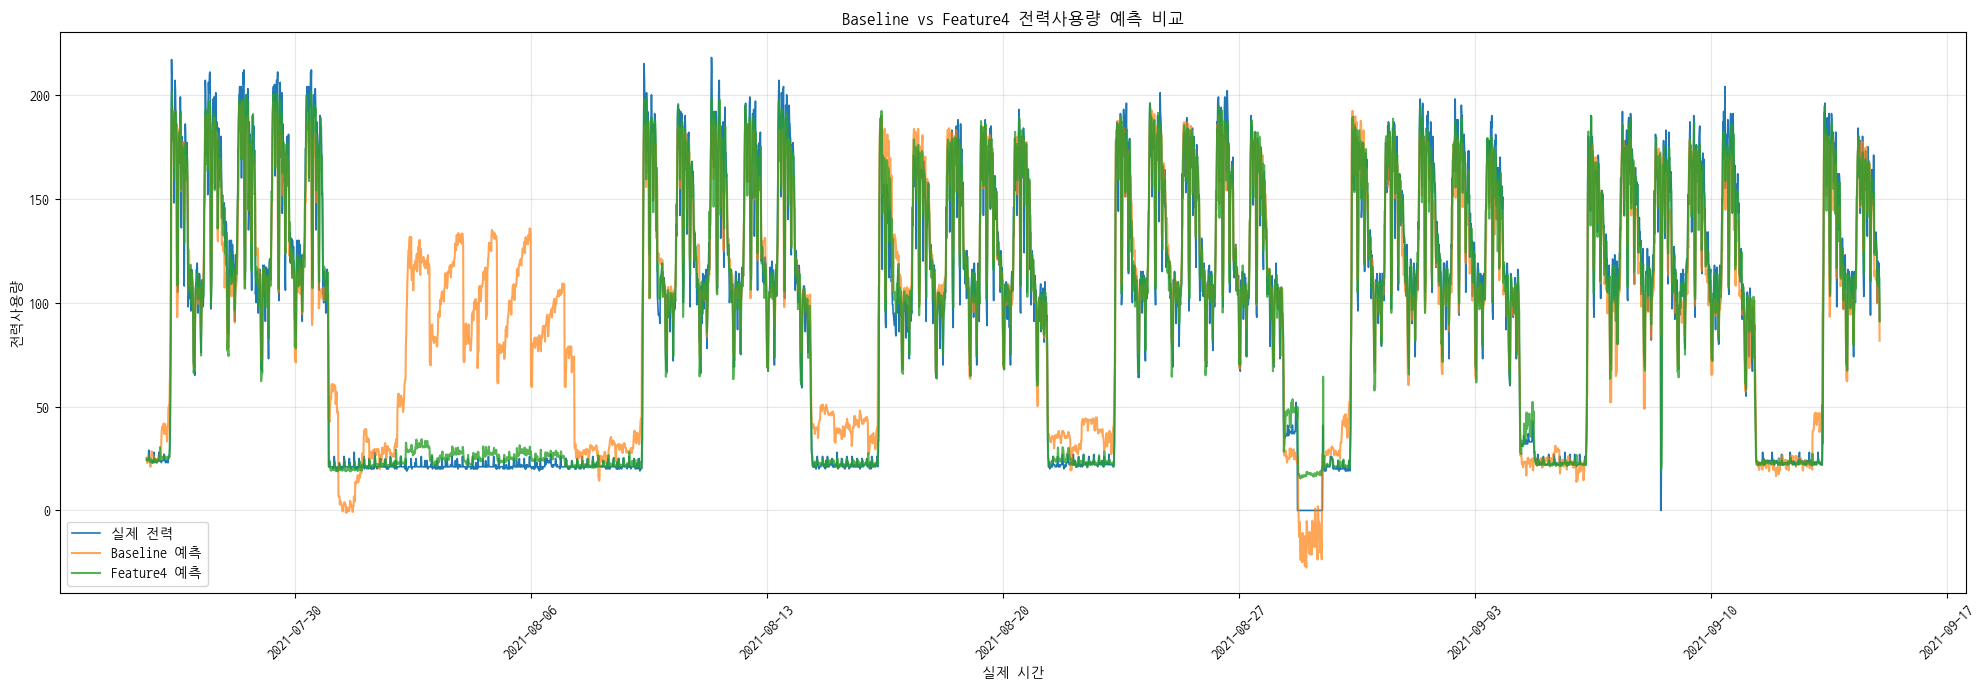

In [14]:
# ============================================================
# #13. 실제값 / Baseline / Feature4 예측 비교
# ============================================================

test_time = (
    pd.to_datetime(
        test_df['날짜'].astype(str),
        format='%Y%m%d'
    )
    + pd.to_timedelta(
        test_df['시간'],
        unit='h'
    )
    + pd.to_timedelta(
        test_df['분'],
        unit='m'
    )
)

plt.figure(figsize=(20, 7))

plt.plot(
    test_time,
    y_test.values,
    label='실제 전력',
    linewidth=1.2
)

plt.plot(
    test_time,
    baseline_test_pred,
    label='Baseline 예측',
    alpha=0.7
)

plt.plot(
    test_time,
    feature4_test_pred,
    label='Feature4 예측',
    alpha=0.8
)

plt.xlabel('실제 시간')
plt.ylabel('전력사용량')
plt.title('Baseline vs Feature4 전력사용량 예측 비교')

plt.legend()
plt.grid(alpha=0.3)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:
# ============================================================
# #14. Feature4 모델 대규모 오차 분석
# ============================================================

feature4_result = test_df.copy()

feature4_result['실제전력'] = y_test.values
feature4_result['예측전력'] = feature4_test_pred

feature4_result['오차'] = (
    feature4_result['실제전력']
    - feature4_result['예측전력']
)

feature4_result['절대오차'] = np.abs(
    feature4_result['오차']
)

feature4_error_threshold = (
    feature4_result['절대오차']
    .quantile(0.95)
)

feature4_large_error = feature4_result[
    feature4_result['절대오차']
    >= feature4_error_threshold
].copy()

print(
    "Feature4 절대오차 상위 5% 기준:",
    round(feature4_error_threshold, 4)
)

print(
    "대규모 오차 데이터 수:",
    len(feature4_large_error)
)

feature4_large_error[
    [
        '날짜',
        '시간',
        '분',
        '생산량',
        'lag_1_power',
        'lag_4_power',
        'production_change',
        'operation_state',
        '실제전력',
        '예측전력',
        '절대오차'
    ]
].head(30)


Feature4 절대오차 상위 5% 기준: 17.2485
대규모 오차 데이터 수: 247


,날짜,시간,분,생산량,lag_1_power,lag_4_power,production_change,operation_state,실제전력,예측전력,절대오차
19802,20210726,7,45,0,50.0,26.0,0.0,비생산지속,75,55.584629,19.415371
19803,20210726,7,60,0,75.0,27.0,0.0,비생산지속,127,93.835953,33.164047
19805,20210726,8,30,805,177.0,50.0,0.0,생산지속,217,193.796143,23.203857
19815,20210726,10,60,1149,191.0,186.0,0.0,생산지속,207,189.128815,17.871185
19832,20210726,15,15,2463,185.0,176.0,1794.0,생산지속,137,154.416946,17.416946
19833,20210726,15,30,2463,137.0,182.0,0.0,생산지속,136,165.874619,29.874619
19840,20210726,17,15,6579,173.0,163.0,5341.0,생산지속,122,139.876968,17.876968
19841,20210726,17,30,6579,122.0,163.0,0.0,생산지속,108,128.769058,20.769058
19844,20210726,18,15,1120,169.0,122.0,-5459.0,생산지속,186,167.436646,18.563354
19851,20210726,19,60,3479,160.0,162.0,0.0,생산지속,122,145.557281,23.557281


                        변수       중요도
0              lag_1_power  0.556145
1                      인건비  0.133685
2              lag_4_power  0.094920
3                      생산량  0.065270
4                       시간  0.027616
5                        m  0.025733
6                      day  0.022435
7     operation_state_생산시작  0.014470
8                        분  0.010838
9        production_change  0.010159
10                    공장인원  0.009349
11                전기요금(계절)  0.005634
12                      기온  0.003905
13    operation_state_생산지속  0.003731
14  operation_state_생산종료전환  0.003234
15                      습도  0.003219
16                       d  0.003185
17   operation_state_비생산지속  0.002953
18                      풍속  0.002336
19                     강수량  0.001183


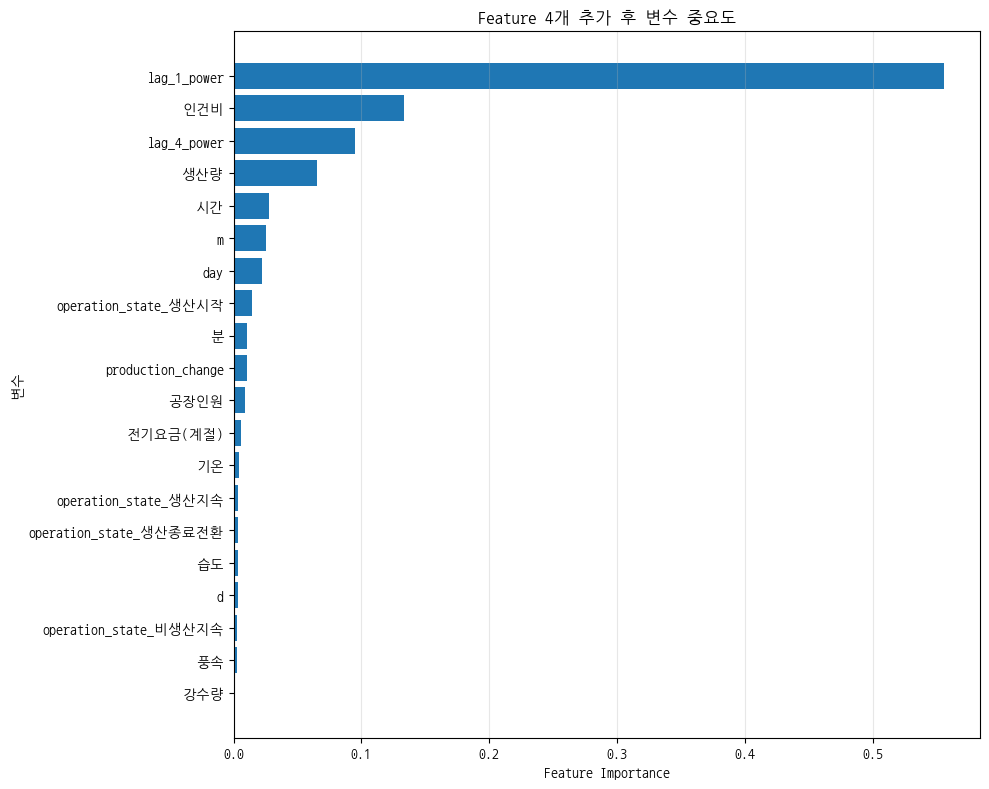

In [16]:
# ============================================================
# #15. Feature4 모델 변수 중요도
# ============================================================

feature_importance = pd.DataFrame({
    '변수': X_feature4.columns,
    '중요도': feature4_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        '중요도',
        ascending=False
    )
    .reset_index(drop=True)
)

print(feature_importance)

plot_data = (
    feature_importance
    .sort_values(
        '중요도',
        ascending=True
    )
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data['변수'],
    plot_data['중요도']
)

plt.xlabel('Feature Importance')
plt.ylabel('변수')
plt.title('Feature 4개 추가 후 변수 중요도')

plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Persistence Baseline

`Persistence`는 단순히 다음 값을 직전 실제 전력값으로 예측합니다.

\[
\hat{P}_t = P_{t-1}
\]

Feature4 모델이 이 단순한 시계열 기준보다 실제로 더 나은지 확인합니다.


In [17]:
# ============================================================
# #16. Persistence Baseline vs Feature4
# ============================================================

persistence_pred = (
    df_exp['lag_1_power']
    .iloc[split_idx:]
    .values
)

persistence_metrics = regression_metrics(
    y_test,
    persistence_pred
)

persistence_comparison = pd.DataFrame({
    '모델': [
        'Persistence',
        'Feature4 XGBoost'
    ],

    'MAE': [
        persistence_metrics['MAE'],
        feature4_test_metrics['MAE']
    ],

    'RMSE': [
        persistence_metrics['RMSE'],
        feature4_test_metrics['RMSE']
    ],

    'R2': [
        persistence_metrics['R2'],
        feature4_test_metrics['R2']
    ]
})

print(persistence_comparison.round(4))

print("\n========== XGBoost 개선량 ==========")

print(
    f"R² 개선 : "
    f"{feature4_test_metrics['R2'] - persistence_metrics['R2']:+.4f}"
)

print(
    f"MAE 감소 : "
    f"{persistence_metrics['MAE'] - feature4_test_metrics['MAE']:+.4f}"
)

print(
    f"RMSE 감소 : "
    f"{persistence_metrics['RMSE'] - feature4_test_metrics['RMSE']:+.4f}"
)


                 모델     MAE     RMSE      R2
0       Persistence  7.6257  13.5048  0.9527
1  Feature4 XGBoost  5.7056   8.1987  0.9826

========== XGBoost 개선량 ==========
R² 개선 : +0.0299
MAE 감소 : +1.9201
RMSE 감소 : +5.3062


현재 Colab 실행에서 확인했던 Persistence Test R²는 약 **0.9527**, Feature4 Test R²는 약 **0.9826**이었습니다.


## 6. TimeSeriesSplit 검증

단일 8:2 분할의 우연성을 줄이기 위해 5개 시간구간에서 반복 검증합니다.

각 Fold에서도 Validation 시점의 `lag_1_power`는 직전 **실제 관측 전력**을 사용하므로, 이 검증은 **15분 ahead rolling prediction** 성능 검증입니다.


In [18]:
# ============================================================
# #17. TimeSeriesSplit 5-Fold 검증
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=5
)

cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(X_feature4),
    start=1
):
    X_train_cv = X_feature4.iloc[train_idx]
    X_valid_cv = X_feature4.iloc[valid_idx]

    y_train_cv = y_feature4.iloc[train_idx]
    y_valid_cv = y_feature4.iloc[valid_idx]

    model_cv = make_xgb_model()

    model_cv.fit(
        X_train_cv,
        y_train_cv
    )

    xgb_pred_cv = model_cv.predict(
        X_valid_cv
    )

    xgb_metrics_cv = regression_metrics(
        y_valid_cv,
        xgb_pred_cv
    )

    # 동일 Validation 구간 Persistence
    persistence_pred_cv = (
        df_exp['lag_1_power']
        .iloc[valid_idx]
        .values
    )

    persistence_metrics_cv = regression_metrics(
        y_valid_cv,
        persistence_pred_cv
    )

    valid_dates = df_exp.iloc[valid_idx]['날짜']

    cv_results.append({
        'Fold': fold,
        '검증 시작': valid_dates.iloc[0],
        '검증 종료': valid_dates.iloc[-1],

        'XGB MAE': xgb_metrics_cv['MAE'],
        'XGB RMSE': xgb_metrics_cv['RMSE'],
        'XGB R2': xgb_metrics_cv['R2'],

        'Persistence MAE': persistence_metrics_cv['MAE'],
        'Persistence RMSE': persistence_metrics_cv['RMSE'],
        'Persistence R2': persistence_metrics_cv['R2']
    })

cv_results = pd.DataFrame(cv_results)

cv_results.round(4)


,Fold,검증 시작,검증 종료,XGB MAE,XGB RMSE,XGB R2,Persistence MAE,Persistence RMSE,Persistence R2
0,1,20210212,20210327,6.6818,10.1486,0.9681,8.0910,13.6346,0.9425
1,2,20210327,20210509,7.7590,11.0616,0.9609,8.4410,14.6906,0.9310
2,3,20210509,20210621,5.1416,7.1483,0.9831,8.1795,13.8806,0.9361
3,4,20210621,20210803,6.5037,9.9057,0.9731,8.6110,14.5019,0.9423
4,5,20210803,20210914,5.6518,8.2545,0.9816,7.6490,13.3190,0.9520


========== Feature4 XGBoost ==========
평균 MAE  : 6.3476
평균 RMSE : 9.3038
평균 R²   : 0.9733
R² 표준편차: 0.0093

========== Persistence ==========
평균 MAE  : 8.1943
평균 RMSE : 14.0053
평균 R²   : 0.9408
R² 표준편차: 0.0079


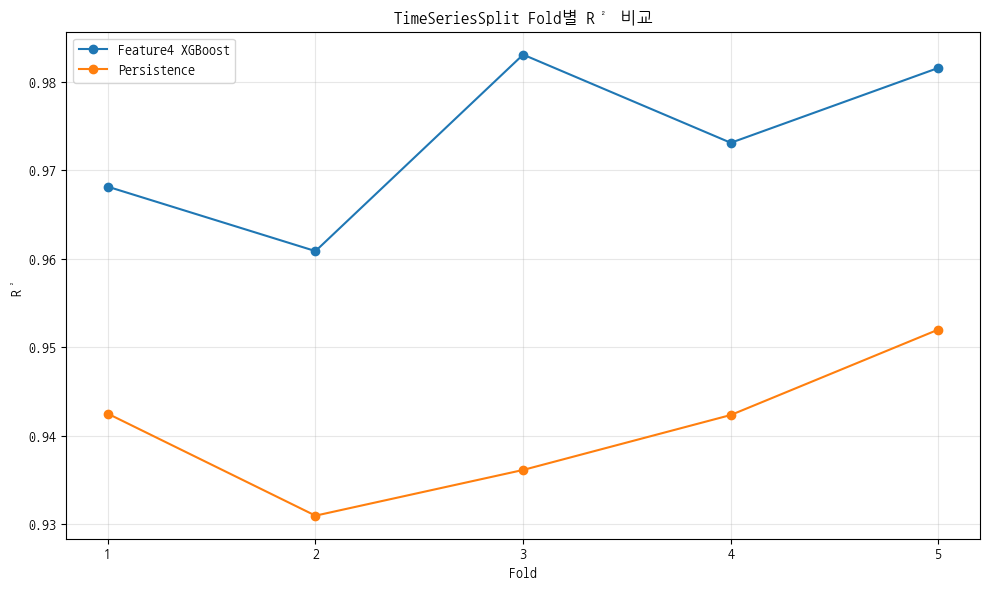

In [19]:
# ============================================================
# #18. TimeSeriesSplit 평균 성능 및 Fold별 R²
# ============================================================

print("========== Feature4 XGBoost ==========")
print(f"평균 MAE  : {cv_results['XGB MAE'].mean():.4f}")
print(f"평균 RMSE : {cv_results['XGB RMSE'].mean():.4f}")
print(f"평균 R²   : {cv_results['XGB R2'].mean():.4f}")
print(f"R² 표준편차: {cv_results['XGB R2'].std():.4f}")

print("\n========== Persistence ==========")
print(f"평균 MAE  : {cv_results['Persistence MAE'].mean():.4f}")
print(f"평균 RMSE : {cv_results['Persistence RMSE'].mean():.4f}")
print(f"평균 R²   : {cv_results['Persistence R2'].mean():.4f}")
print(f"R² 표준편차: {cv_results['Persistence R2'].std():.4f}")


plt.figure(figsize=(10, 6))

plt.plot(
    cv_results['Fold'],
    cv_results['XGB R2'],
    marker='o',
    label='Feature4 XGBoost'
)

plt.plot(
    cv_results['Fold'],
    cv_results['Persistence R2'],
    marker='o',
    label='Persistence'
)

plt.xlabel('Fold')
plt.ylabel('R²')
plt.title('TimeSeriesSplit Fold별 R² 비교')

plt.xticks(cv_results['Fold'])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


현재 Colab 실행에서 확인했던 TimeSeriesSplit 평균 성능은 다음과 같습니다.

- Feature4 XGBoost 평균 R² ≈ **0.9733**
- Persistence 평균 R² ≈ **0.9408**
- Feature4 XGBoost R² 표준편차 ≈ **0.0093**


## 7. 제출용 파일 저장

`df_feature4`에는 원본 데이터 + 정확히 4개 Feature만 포함됩니다.  
`feature4_prediction_result.csv`에는 Test 구간의 실제값, 예측값, 오차가 저장됩니다.


In [20]:
# ============================================================
# #19. Feature4 데이터 / 예측결과 저장
# ============================================================

feature_data_name = 'Power15MinClean_Feature4.csv'
prediction_name = 'feature4_prediction_result.csv'

# 기존 17개 + 정확히 4개 Feature
df_feature4.to_csv(
    feature_data_name,
    index=False,
    encoding='utf-8-sig'
)

# Test 예측 결과
feature4_result.to_csv(
    prediction_name,
    index=False,
    encoding='utf-8-sig'
)

print("저장 완료:")
print("-", feature_data_name, df_feature4.shape)
print("-", prediction_name, feature4_result.shape)

# 필요할 때 아래 주석을 해제해서 다운로드
# files.download(feature_data_name)
# files.download(prediction_name)


저장 완료:
- Power15MinClean_Feature4.csv (24672, 21)
- feature4_prediction_result.csv (4934, 25)


In [21]:
# ============================================================
# #20. 최종 Feature4 모델 대규모 오차 정의
# ============================================================

error_threshold = (
    feature4_result['절대오차']
    .quantile(0.95)
)

feature4_result['대규모오차'] = (
    feature4_result['절대오차']
    >= error_threshold
)

print(
    f"절대오차 상위 5% 기준값: "
    f"{error_threshold:.4f}"
)

print(
    f"대규모 오차 데이터 수: "
    f"{feature4_result['대규모오차'].sum()}"
)

print(
    f"전체 Test 데이터 수: "
    f"{len(feature4_result)}"
)

절대오차 상위 5% 기준값: 17.2485
대규모 오차 데이터 수: 247
전체 Test 데이터 수: 4934


In [22]:
# ============================================================
# #21. 생산량 조건별 대규모 오차율
# ============================================================

result_analysis = feature4_result.copy()

# 생산량 0은 별도 구분
positive_prod = (
    result_analysis.loc[
        result_analysis['생산량'] > 0,
        '생산량'
    ]
)

# 생산량 > 0 구간을 4분위수로 구분
prod_quartile = pd.qcut(
    positive_prod,
    q=4,
    duplicates='drop'
)

result_analysis['생산량구간'] = '생산량=0'

result_analysis.loc[
    result_analysis['생산량'] > 0,
    '생산량구간'
] = prod_quartile.astype(str)


prod_error_analysis = (
    result_analysis
    .groupby('생산량구간')
    .agg(
        데이터수=('절대오차', 'size'),
        평균생산량=('생산량', 'mean'),
        평균절대오차=('절대오차', 'mean'),
        RMSE=(
            '오차',
            lambda x: np.sqrt(np.mean(x**2))
        ),
        대규모오차수=('대규모오차', 'sum'),
        대규모오차율=('대규모오차', 'mean')
    )
    .reset_index()
)

prod_error_analysis['대규모오차율'] *= 100

prod_error_analysis.round(4)

,생산량구간,데이터수,평균생산량,평균절대오차,RMSE,대규모오차수,대규모오차율
0,"(1.999, 135.0]",720,61.0167,6.0258,8.4707,19,2.6389
1,"(1238.0, 7913.0]",716,2301.2011,8.5550,10.6103,70,9.7765
2,"(135.0, 510.0]",720,286.1611,6.7110,8.8245,37,5.1389
3,"(510.0, 1238.0]",716,882.8547,8.0380,10.2420,64,8.9385
4,생산량=0,2062,0.0000,3.4433,5.7515,57,2.7643


In [23]:
# ============================================================
# #22. 생산량 변화 방향별 오차 분석
# ============================================================

result_analysis['생산량변화상태'] = np.select(
    [
        result_analysis['production_change'] < 0,
        result_analysis['production_change'] == 0,
        result_analysis['production_change'] > 0
    ],
    [
        '생산량 감소',
        '생산량 변화없음',
        '생산량 증가'
    ],
    default='기타'
)


production_change_analysis = (
    result_analysis
    .groupby('생산량변화상태')
    .agg(
        데이터수=('절대오차', 'size'),
        평균생산량변화=('production_change', 'mean'),
        평균절대오차=('절대오차', 'mean'),
        대규모오차수=('대규모오차', 'sum'),
        대규모오차율=('대규모오차', 'mean')
    )
    .reset_index()
)

production_change_analysis['대규모오차율'] *= 100

production_change_analysis.round(4)

,생산량변화상태,데이터수,평균생산량변화,평균절대오차,대규모오차수,대규모오차율
0,생산량 감소,346,-839.1012,7.8208,26,7.5145
1,생산량 변화없음,4184,0.0000,5.2800,184,4.3977
2,생산량 증가,404,719.6386,8.3018,37,9.1584


In [24]:
# ============================================================
# #23. 생산 전환상태별 오차 분석
# ============================================================

operation_error_analysis = (
    result_analysis
    .groupby('operation_state')
    .agg(
        데이터수=('절대오차', 'size'),
        평균절대오차=('절대오차', 'mean'),
        RMSE=(
            '오차',
            lambda x: np.sqrt(np.mean(x**2))
        ),
        대규모오차수=('대규모오차', 'sum'),
        대규모오차율=('대규모오차', 'mean')
    )
    .reset_index()
)

operation_error_analysis['대규모오차율'] *= 100

operation_error_analysis.round(4)

,operation_state,데이터수,평균절대오차,RMSE,대규모오차수,대규모오차율
0,비생산지속,2029,3.3760,5.6850,56,2.7600
1,생산시작,34,8.5722,12.2254,3,8.8235
2,생산종료전환,33,7.5851,8.9347,1,3.0303
3,생산지속,2838,7.3149,9.5413,187,6.5891


In [25]:
# ============================================================
# #24. 공장인원 조건별 오차 분석
# ============================================================

result_analysis['인원상태'] = np.where(
    result_analysis['공장인원'] == 0,
    '공장인원=0',
    '공장인원>0'
)

worker_error_analysis = (
    result_analysis
    .groupby('인원상태')
    .agg(
        데이터수=('절대오차', 'size'),
        평균절대오차=('절대오차', 'mean'),
        대규모오차수=('대규모오차', 'sum'),
        대규모오차율=('대규모오차', 'mean')
    )
    .reset_index()
)

worker_error_analysis['대규모오차율'] *= 100

worker_error_analysis.round(4)

,인원상태,데이터수,평균절대오차,대규모오차수,대규모오차율
0,공장인원=0,1994,2.9704,23,1.1535
1,공장인원>0,2940,7.5606,224,7.6190


In [26]:
# ============================================================
# #25. 생산조건 조합별 대규모 오차율
# ============================================================

combined_error_analysis = (
    result_analysis
    .groupby(
        [
            'operation_state',
            '생산량변화상태'
        ]
    )
    .agg(
        데이터수=('절대오차', 'size'),
        평균절대오차=('절대오차', 'mean'),
        대규모오차수=('대규모오차', 'sum'),
        대규모오차율=('대규모오차', 'mean')
    )
    .reset_index()
)

combined_error_analysis['대규모오차율'] *= 100

# 표본이 너무 적은 조합은 제외
combined_error_analysis = (
    combined_error_analysis[
        combined_error_analysis['데이터수'] >= 30
    ]
    .sort_values(
        '대규모오차율',
        ascending=False
    )
)

combined_error_analysis.round(4)

,operation_state,생산량변화상태,데이터수,평균절대오차,대규모오차수,대규모오차율
5,생산지속,생산량 증가,370,8.2769,34,9.1892
1,생산시작,생산량 증가,34,8.5722,3,8.8235
3,생산지속,생산량 감소,313,7.8457,25,7.9872
4,생산지속,생산량 변화없음,2155,7.0726,128,5.9397
2,생산종료전환,생산량 감소,33,7.5851,1,3.0303
0,비생산지속,생산량 변화없음,2029,3.3760,56,2.7600


In [27]:
# ============================================================
# #26. 대규모 오차의 과소예측 / 과대예측 분석
# ============================================================

large_error_final = result_analysis[
    result_analysis['대규모오차']
].copy()

large_error_final['오차방향'] = np.where(
    large_error_final['오차'] > 0,
    '과소예측',
    '과대예측'
)

error_direction_analysis = (
    large_error_final
    .groupby('오차방향')
    .agg(
        데이터수=('절대오차', 'size'),
        평균절대오차=('절대오차', 'mean'),
        평균실제전력=('실제전력', 'mean'),
        평균예측전력=('예측전력', 'mean')
    )
    .reset_index()
)

error_direction_analysis.round(4)

,오차방향,데이터수,평균절대오차,평균실제전력,평균예측전력
0,과대예측,126,21.9716,83.3413,105.312897
1,과소예측,121,22.4475,165.9256,143.478195


## 9. 월별 최대전력 피크 조건 분석

본 분석에서는 각 월의 모든 15분 관측값 중 가장 높은 전력사용량을 해당 월의 **최대전력 피크**로 정의합니다.

\[
P^{peak}_m = \max_{t \in m} P_t
\]

같은 월에 최댓값이 여러 번 나타나면 임의로 한 시점만 선택하지 않고, 해당 시점을 모두 월별 최대전력 피크 발생 시점으로 포함합니다.

월별 최대값만으로는 표본 수가 적으므로, 공식 피크 분석과 별도로 각 월의 상위 5% 전력 구간을 **고전력 위험구간**으로 정의하여 조건 분석을 보조합니다. 고전력 위험구간은 월별 최대전력 피크와 동일한 개념이 아니며, 최대피크가 발생하기 쉬운 운영조건을 안정적으로 파악하기 위한 보조 기준입니다.


In [28]:
# ============================================================
# #27. 분석용 시각 및 연월 생성
# ============================================================

peak_df = df_feature4.copy()

# 시간=8, 분=60과 같은 값도 09:00으로 정상 변환됨
peak_df['기준일자'] = pd.to_datetime(
    peak_df['날짜'].astype(str),
    format='%Y%m%d'
)

peak_df['timestamp'] = (
    peak_df['기준일자']
    + pd.to_timedelta(peak_df['시간'], unit='h')
    + pd.to_timedelta(peak_df['분'], unit='m')
)

peak_df = (
    peak_df
    .sort_values('timestamp')
    .reset_index(drop=True)
)

# 월 구분은 원자료의 날짜 기준으로 유지
# (예: 1월 31일 23시 60분은 1월 관측으로 분류)
peak_df['연월'] = peak_df['기준일자'].dt.to_period('M').astype(str)
peak_df['실제시각'] = peak_df['timestamp'].dt.hour

print('분석 기간:', peak_df['timestamp'].min(), '~', peak_df['timestamp'].max())
print('전체 관측 수:', len(peak_df))
print('분석 월 수:', peak_df['연월'].nunique())
print('\n월별 관측 수:')
display(peak_df.groupby('연월').size().rename('관측수').reset_index())


분석 기간: 2021-01-01 00:15:00 ~ 2021-09-15 00:00:00
전체 관측 수: 24672
분석 월 수: 9

월별 관측 수:


,연월,관측수
0,2021-01,2976
1,2021-02,2688
2,2021-03,2976
3,2021-04,2880
4,2021-05,2976
5,2021-06,2880
6,2021-07,2976
7,2021-08,2976
8,2021-09,1344


In [29]:
# ============================================================
# #28. 월별 최대전력 피크 정의
# ============================================================

monthly_max_power = (
    peak_df
    .groupby('연월')['전력사용량']
    .transform('max')
)

peak_df['월별최대피크여부'] = (
    peak_df['전력사용량'] == monthly_max_power
)

# 동률이면 해당 시점을 모두 포함
monthly_peak = (
    peak_df.loc[peak_df['월별최대피크여부']]
    .copy()
    .sort_values(['연월', 'timestamp'])
    .reset_index(drop=True)
)

monthly_peak_summary = (
    monthly_peak
    .groupby('연월')
    .agg(
        월별최대전력=('전력사용량', 'max'),
        최대값발생횟수=('전력사용량', 'size'),
        최초발생시각=('timestamp', 'min'),
        최종발생시각=('timestamp', 'max')
    )
    .reset_index()
)

print('월 수:', peak_df['연월'].nunique())
print('월별 최대피크 발생 시점 수(동률 포함):', len(monthly_peak))
print('동률 피크가 존재하는 월 수:',
      (monthly_peak_summary['최대값발생횟수'] > 1).sum())

display(monthly_peak_summary)


월 수: 9
월별 최대피크 발생 시점 수(동률 포함): 9
동률 피크가 존재하는 월 수: 0


,연월,월별최대전력,최대값발생횟수,최초발생시각,최종발생시각
0,2021-01,222,1,2021-01-29 08:30:00,2021-01-29 08:30:00
1,2021-02,198,1,2021-02-15 08:45:00,2021-02-15 08:45:00
2,2021-03,222,1,2021-03-29 08:30:00,2021-03-29 08:30:00
3,2021-04,199,1,2021-04-07 09:00:00,2021-04-07 09:00:00
4,2021-05,199,1,2021-05-06 09:00:00,2021-05-06 09:00:00
5,2021-06,222,1,2021-06-29 08:30:00,2021-06-29 08:30:00
6,2021-07,222,1,2021-07-19 11:30:00,2021-07-19 11:30:00
7,2021-08,218,1,2021-08-11 08:45:00,2021-08-11 08:45:00
8,2021-09,204,1,2021-09-10 10:00:00,2021-09-10 10:00:00


In [30]:
# ============================================================
# #29. 월별 최대전력 피크 발생 시점 상세
# ============================================================

peak_detail_columns = [
    '연월', 'timestamp', '전력사용량',
    '생산량', 'production_change', 'operation_state',
    '공장인원', '인건비', '기온', '습도',
    'lag_1_power', 'lag_4_power'
]

display(monthly_peak[peak_detail_columns])


,연월,timestamp,전력사용량,생산량,production_change,operation_state,공장인원,인건비,기온,습도,lag_1_power,lag_4_power
0,2021-01,2021-01-29 08:30:00,222,364,0.0,생산지속,0.450495,1.5,-6.8,37,190.0,120.0
1,2021-02,2021-02-15 08:45:00,198,635,0.0,생산지속,0.845539,1.5,10.2,94,196.0,144.0
2,2021-03,2021-03-29 08:30:00,222,1644,0.0,생산지속,2.034653,1.5,14.0,72,190.0,120.0
3,2021-04,2021-04-07 09:00:00,199,669,0.0,생산지속,0.904054,1.5,13.6,43,190.0,95.0
4,2021-05,2021-05-06 09:00:00,199,424,0.0,생산지속,0.572973,1.5,14.6,31,190.0,95.0
5,2021-06,2021-06-29 08:30:00,222,893,0.0,생산지속,1.105198,1.5,23.3,77,190.0,120.0
6,2021-07,2021-07-19 11:30:00,222,1280,0.0,생산지속,1.606023,1.0,28.4,75,182.0,180.0
7,2021-08,2021-08-11 08:45:00,218,783,0.0,생산지속,0.964286,1.5,25.6,94,206.0,142.0
8,2021-09,2021-09-10 10:00:00,204,1038,0.0,생산지속,1.410326,1.0,21.8,95,179.0,192.0


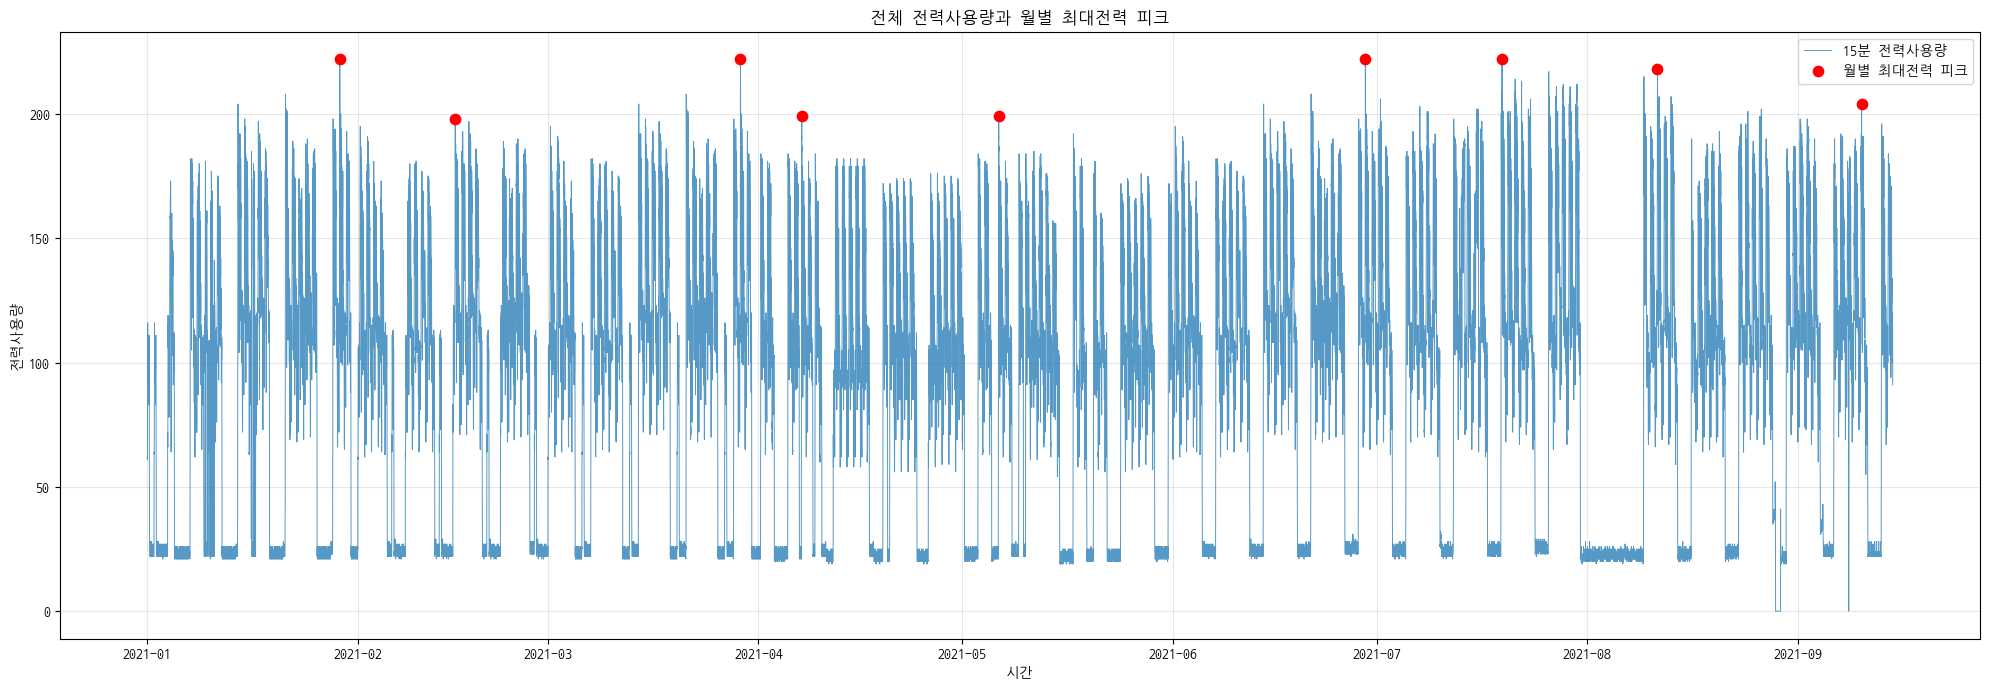

In [31]:
# ============================================================
# #30. 전체 전력 추이와 월별 최대전력 피크
# ============================================================

plt.figure(figsize=(20, 7))

plt.plot(
    peak_df['timestamp'],
    peak_df['전력사용량'],
    linewidth=0.7,
    alpha=0.75,
    label='15분 전력사용량'
)

plt.scatter(
    monthly_peak['timestamp'],
    monthly_peak['전력사용량'],
    color='red',
    s=55,
    zorder=3,
    label='월별 최대전력 피크'
)

plt.xlabel('시간')
plt.ylabel('전력사용량')
plt.title('전체 전력사용량과 월별 최대전력 피크')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


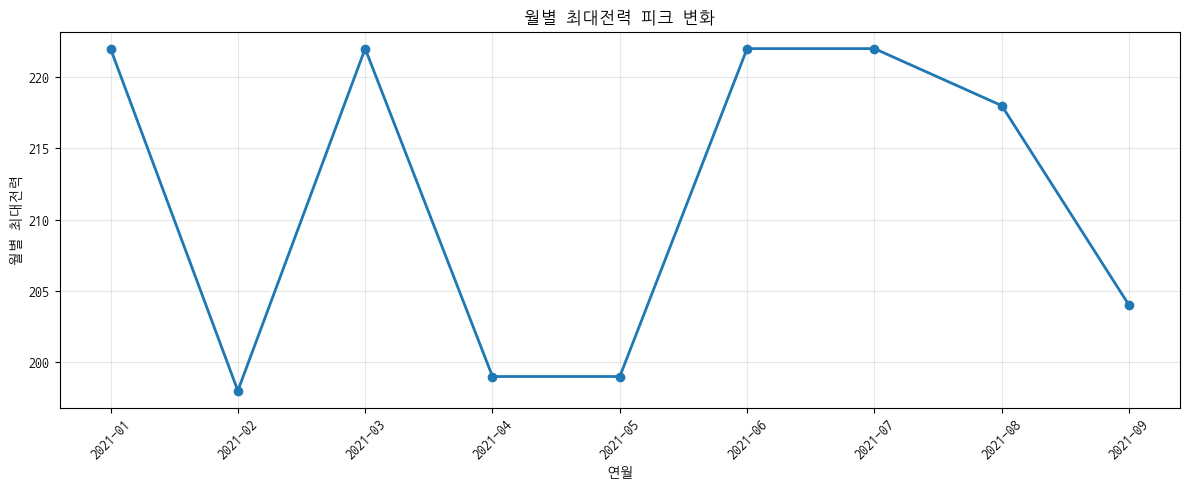

,연월,월별최대전력
0,2021-01,222
1,2021-02,198
2,2021-03,222
3,2021-04,199
4,2021-05,199
5,2021-06,222
6,2021-07,222
7,2021-08,218
8,2021-09,204


In [32]:
# ============================================================
# #31. 월별 최대전력 변화
# ============================================================

monthly_peak_value = (
    monthly_peak
    .groupby('연월', as_index=False)['전력사용량']
    .max()
    .rename(columns={'전력사용량': '월별최대전력'})
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_peak_value['연월'],
    monthly_peak_value['월별최대전력'],
    marker='o',
    linewidth=2
)
plt.xlabel('연월')
plt.ylabel('월별 최대전력')
plt.title('월별 최대전력 피크 변화')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_peak_value)


In [33]:
# ============================================================
# #32. 피크 조건 분석을 위한 파생 범주 생성
# ============================================================

def make_change_state(series):
    return np.select(
        [series < 0, series == 0, series > 0],
        ['생산량 감소', '생산량 변화없음', '생산량 증가'],
        default='기타'
    )


peak_df['생산량변화상태'] = make_change_state(
    peak_df['production_change']
)
monthly_peak['생산량변화상태'] = make_change_state(
    monthly_peak['production_change']
)

peak_df['인원상태'] = np.where(
    peak_df['공장인원'] > 0,
    '공장인원>0',
    '공장인원=0'
)
monthly_peak['인원상태'] = np.where(
    monthly_peak['공장인원'] > 0,
    '공장인원>0',
    '공장인원=0'
)

# 생산량=0은 별도 구분하고, 양수 생산량은 전체 데이터 기준 4분위 구간화
positive_production = peak_df.loc[peak_df['생산량'] > 0, '생산량']
_, production_bins = pd.qcut(
    positive_production,
    q=4,
    retbins=True,
    duplicates='drop'
)

def add_production_group(data):
    result = pd.Series('생산량=0', index=data.index, dtype='object')
    positive_mask = data['생산량'] > 0
    result.loc[positive_mask] = pd.cut(
        data.loc[positive_mask, '생산량'],
        bins=production_bins,
        include_lowest=True
    ).astype(str)
    return result


peak_df['생산량구간'] = add_production_group(peak_df)
monthly_peak['생산량구간'] = add_production_group(monthly_peak)

print('피크 조건 분석용 범주 생성 완료')


피크 조건 분석용 범주 생성 완료


In [34]:
# ============================================================
# #33. 범주별 월별 최대피크 집중도 계산 함수
# ============================================================

def peak_condition_table(all_data, peak_data, column):
    overall_count = all_data[column].value_counts(dropna=False)
    peak_count = peak_data[column].value_counts(dropna=False)

    result = pd.DataFrame({
        '전체관측수': overall_count,
        '월별최대피크발생수': peak_count
    }).fillna(0)

    result['전체데이터비율(%)'] = (
        result['전체관측수'] / len(all_data) * 100
    )
    result['피크내비율(%)'] = (
        result['월별최대피크발생수'] / len(peak_data) * 100
    )
    result['피크집중도'] = (
        result['피크내비율(%)']
        / result['전체데이터비율(%)']
    )
    result['조건별피크발생률(%)'] = (
        result['월별최대피크발생수']
        / result['전체관측수']
        * 100
    )

    return (
        result
        .reset_index(names=column)
        .sort_values('피크집중도', ascending=False)
    )


,실제시각,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
8,8,1028,5.0,4.167,55.556,13.333,0.486
9,9,1028,2.0,4.167,22.222,5.333,0.195
11,11,1028,1.0,4.167,11.111,2.667,0.097
10,10,1028,1.0,4.167,11.111,2.667,0.097
0,0,1028,0.0,4.167,0.000,0.000,0.000
1,1,1028,0.0,4.167,0.000,0.000,0.000
2,2,1028,0.0,4.167,0.000,0.000,0.000
3,3,1028,0.0,4.167,0.000,0.000,0.000
7,7,1028,0.0,4.167,0.000,0.000,0.000
6,6,1028,0.0,4.167,0.000,0.000,0.000


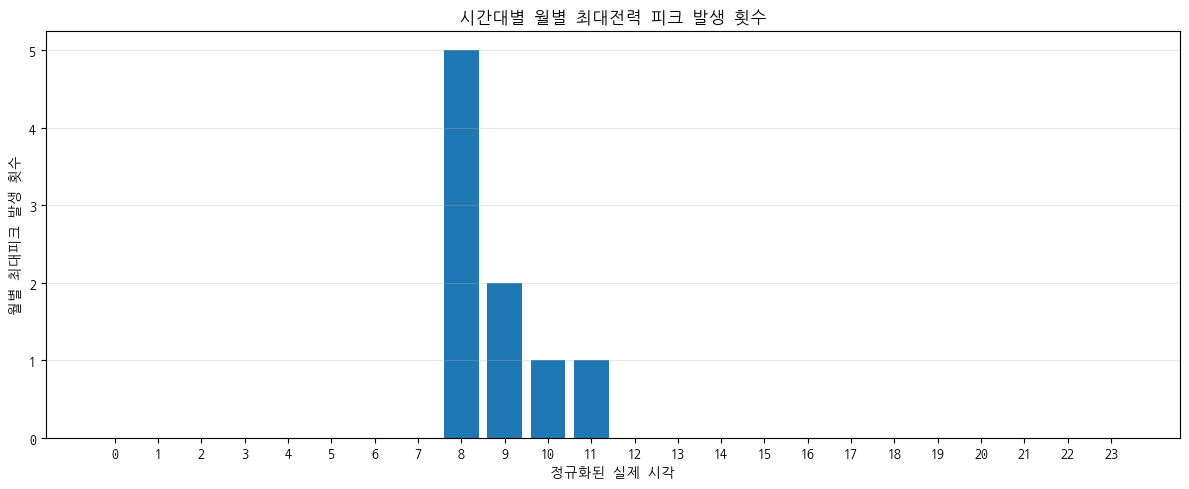

In [35]:
# ============================================================
# #34. 월별 최대피크 발생 시간대 분석
# ============================================================

peak_hour_analysis = peak_condition_table(
    peak_df,
    monthly_peak,
    '실제시각'
)

display(peak_hour_analysis.round(3))

plt.figure(figsize=(12, 5))
hour_count = (
    monthly_peak['실제시각']
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)
plt.bar(hour_count.index, hour_count.values)
plt.xlabel('정규화된 실제 시각')
plt.ylabel('월별 최대피크 발생 횟수')
plt.title('시간대별 월별 최대전력 피크 발생 횟수')
plt.xticks(range(24))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:
# ============================================================
# #35. 생산량 구간별 월별 최대피크 조건
# ============================================================

monthly_peak_production = peak_condition_table(
    peak_df,
    monthly_peak,
    '생산량구간'
)

display(monthly_peak_production.round(3))


,생산량구간,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
3,"(498.0, 1175.0]",3496,5.0,14.170,55.556,3.921,0.143
2,"(1175.0, 9830.0]",3508,2.0,14.219,22.222,1.563,0.057
1,"(116.0, 498.0]",3524,2.0,14.283,22.222,1.556,0.057
0,"(0.999, 116.0]",3516,0.0,14.251,0.000,0.000,0.000
4,생산량=0,10628,0.0,43.077,0.000,0.000,0.000


In [37]:
# ============================================================
# #36. 생산량 변화별 월별 최대피크 조건
# ============================================================

monthly_peak_change = peak_condition_table(
    peak_df,
    monthly_peak,
    '생산량변화상태'
)

display(monthly_peak_change.round(3))


,생산량변화상태,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
2,생산량 변화없음,20939,9.0,84.869,100.0,1.178,0.043
0,기타,1,0.0,0.004,0.0,0.000,0.000
1,생산량 감소,1800,0.0,7.296,0.0,0.000,0.000
3,생산량 증가,1932,0.0,7.831,0.0,0.000,0.000


In [38]:
# ============================================================
# #37. 생산상태별 월별 최대피크 조건
# ============================================================

monthly_peak_operation = peak_condition_table(
    peak_df,
    monthly_peak,
    'operation_state'
)

display(monthly_peak_operation.round(3))


,operation_state,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
3,생산지속,13818,9.0,56.007,100.0,1.785,0.065
0,비생산지속,10402,0.0,42.161,0.0,0.000,0.000
1,생산시작,226,0.0,0.916,0.0,0.000,0.000
2,생산종료전환,225,0.0,0.912,0.0,0.000,0.000
4,None,1,0.0,0.004,0.0,0.000,0.000


In [39]:
# ============================================================
# #38. 공장인원 조건별 월별 최대피크 분석
# ============================================================

monthly_peak_worker = peak_condition_table(
    peak_df,
    monthly_peak,
    '인원상태'
)

display(monthly_peak_worker.round(3))


,인원상태,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
1,공장인원>0,14044,9.0,56.923,100.0,1.757,0.064
0,공장인원=0,10628,0.0,43.077,0.0,0.000,0.000


In [40]:
# ============================================================
# #39. 전체 구간과 월별 최대피크의 주요 수치 비교
# ============================================================

peak_numeric_features = [
    '전력사용량', '생산량', 'production_change',
    '공장인원', '인건비', '기온', '습도',
    'lag_1_power', 'lag_4_power'
]

monthly_peak_numeric_summary = pd.DataFrame({
    '전체 평균': peak_df[peak_numeric_features].mean(),
    '월별 최대피크 평균': monthly_peak[peak_numeric_features].mean(),
    '전체 중앙값': peak_df[peak_numeric_features].median(),
    '월별 최대피크 중앙값': monthly_peak[peak_numeric_features].median()
})

monthly_peak_numeric_summary['피크/전체 평균비'] = (
    monthly_peak_numeric_summary['월별 최대피크 평균']
    / monthly_peak_numeric_summary['전체 평균']
)

display(monthly_peak_numeric_summary.round(4))


,전체 평균,월별 최대피크 평균,전체 중앙값,월별 최대피크 중앙값,피크/전체 평균비
전력사용량,93.3125,211.7778,104.000,218.0000,2.2696
생산량,467.3447,858.8889,45.000,783.0000,1.8378
production_change,0.0164,0.0000,0.000,0.0000,0.0000
공장인원,0.9013,1.0993,0.113,0.9643,1.2196
인건비,1.3140,1.3889,1.500,1.5000,1.0570
기온,15.9061,16.0778,17.400,14.6000,1.0108
습도,70.0987,68.6667,74.000,75.0000,0.9796
lag_1_power,93.3126,190.3333,104.000,190.0000,2.0397
lag_4_power,93.3098,134.2222,104.000,120.0000,1.4385


In [41]:

# ============================================================
# #40. 생산상태와 생산량 변화 조합 분석
# ============================================================

peak_df['운영조건조합'] = (
    peak_df['operation_state'].astype(str)
    + ' + '
    + peak_df['생산량변화상태'].astype(str)
)
monthly_peak['운영조건조합'] = (
    monthly_peak['operation_state'].astype(str)
    + ' + '
    + monthly_peak['생산량변화상태'].astype(str)
)

monthly_peak_combination = peak_condition_table(
    peak_df,
    monthly_peak,
    '운영조건조합'
)

display(monthly_peak_combination.round(3))


,운영조건조합,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
5,생산지속 + 생산량 변화없음,10537,9.0,42.708,100.0,2.341,0.085
1,비생산지속 + 생산량 변화없음,10402,0.0,42.161,0.0,0.000,0.000
0,None + 기타,1,0.0,0.004,0.0,0.000,0.000
2,생산시작 + 생산량 증가,226,0.0,0.916,0.0,0.000,0.000
3,생산종료전환 + 생산량 감소,225,0.0,0.912,0.0,0.000,0.000
4,생산지속 + 생산량 감소,1575,0.0,6.384,0.0,0.000,0.000
6,생산지속 + 생산량 증가,1706,0.0,6.915,0.0,0.000,0.000


### 월별 고전력 위험구간 보조 분석

월별 최대전력 피크는 공식 피크 정의이지만 월마다 관측값이 매우 적습니다. 따라서 각 월의 95% 분위수 이상인 관측값을 고전력 위험구간으로 정의하여, 월별 최대피크에서 관찰된 조건이 주변 고전력 구간에서도 반복되는지 확인합니다.

이 보조 분석의 결과는 월별 최대피크 자체의 개수나 정의를 변경하지 않습니다.


In [42]:
# ============================================================
# #41. 월별 상위 5% 고전력 위험구간 정의
# ============================================================

peak_df['월별95%기준'] = (
    peak_df
    .groupby('연월')['전력사용량']
    .transform(lambda x: x.quantile(0.95))
)

peak_df['고전력위험구간'] = (
    peak_df['전력사용량'] >= peak_df['월별95%기준']
)

high_power_df = (
    peak_df.loc[peak_df['고전력위험구간']]
    .copy()
    .reset_index(drop=True)
)

print('전체 관측 수:', len(peak_df))
print('고전력 위험구간 수:', len(high_power_df))
print('고전력 위험구간 비율:',
      f"{len(high_power_df) / len(peak_df) * 100:.2f}%")

display(
    peak_df
    .groupby('연월')
    .agg(
        월별95퍼센트기준=('월별95%기준', 'first'),
        월별최대전력=('전력사용량', 'max'),
        고전력관측수=('고전력위험구간', 'sum')
    )
    .reset_index()
    .round(3)
)


전체 관측 수: 24672
고전력 위험구간 수: 1298
고전력 위험구간 비율: 5.26%


,연월,월별95퍼센트기준,월별최대전력,고전력관측수
0,2021-01,178.00,222,154
1,2021-02,175.00,198,136
2,2021-03,179.25,222,149
3,2021-04,172.00,199,156
4,2021-05,169.00,199,160
5,2021-06,180.00,222,149
6,2021-07,192.00,222,167
7,2021-08,184.00,218,154
8,2021-09,182.00,204,73


In [43]:
# ============================================================
# #42. 고전력 위험구간의 조건별 집중도
# ============================================================

high_power_hour = peak_condition_table(
    peak_df, high_power_df, '실제시각'
)
high_power_production = peak_condition_table(
    peak_df, high_power_df, '생산량구간'
)
high_power_change = peak_condition_table(
    peak_df, high_power_df, '생산량변화상태'
)
high_power_operation = peak_condition_table(
    peak_df, high_power_df, 'operation_state'
)
high_power_worker = peak_condition_table(
    peak_df, high_power_df, '인원상태'
)
high_power_combination = peak_condition_table(
    peak_df, high_power_df, '운영조건조합'
)

print('========== 시간대별 고전력 위험조건 ==========')
display(high_power_hour.round(3))

print('========== 생산량 구간별 고전력 위험조건 ==========')
display(high_power_production.round(3))

print('========== 생산량 변화별 고전력 위험조건 ==========')
display(high_power_change.round(3))

print('========== 생산상태별 고전력 위험조건 ==========')
display(high_power_operation.round(3))

print('========== 공장인원별 고전력 위험조건 ==========')
display(high_power_worker.round(3))

print('========== 운영조건 조합별 고전력 위험조건 ==========')
display(high_power_combination.round(3))


========== 시간대별 고전력 위험조건 ==========


,실제시각,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
9,9,1028,224.0,4.167,17.257,4.142,21.790
11,11,1028,198.0,4.167,15.254,3.661,19.261
8,8,1028,166.0,4.167,12.789,3.069,16.148
10,10,1028,165.0,4.167,12.712,3.051,16.051
14,14,1028,143.0,4.167,11.017,2.644,13.911
13,13,1028,139.0,4.167,10.709,2.570,13.521
15,15,1028,106.0,4.167,8.166,1.960,10.311
16,16,1028,59.0,4.167,4.545,1.091,5.739
12,12,1028,54.0,4.167,4.160,0.998,5.253
18,18,1028,29.0,4.167,2.234,0.536,2.821


========== 생산량 구간별 고전력 위험조건 ==========


,생산량구간,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
3,"(498.0, 1175.0]",3496,544,14.170,41.911,2.958,15.561
2,"(1175.0, 9830.0]",3508,479,14.219,36.903,2.595,13.655
1,"(116.0, 498.0]",3524,147,14.283,11.325,0.793,4.171
4,생산량=0,10628,124,43.077,9.553,0.222,1.167
0,"(0.999, 116.0]",3516,4,14.251,0.308,0.022,0.114


========== 생산량 변화별 고전력 위험조건 ==========


...

,operation_state,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
3,생산지속,13818,1170.0,56.007,90.139,1.609,8.467
1,생산시작,226,4.0,0.916,0.308,0.336,1.770
0,비생산지속,10402,124.0,42.161,9.553,0.227,1.192
2,생산종료전환,225,0.0,0.912,0.000,0.000,0.000
4,None,1,0.0,0.004,0.000,0.000,0.000


========== 공장인원별 고전력 위험조건 ==========


,인원상태,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
0,공장인원>0,14044,1174,56.923,90.447,1.589,8.359
1,공장인원=0,10628,124,43.077,9.553,0.222,1.167


========== 운영조건 조합별 고전력 위험조건 ==========


,운영조건조합,전체관측수,월별최대피크발생수,전체데이터비율(%),피크내비율(%),피크집중도,조건별피크발생률(%)
5,생산지속 + 생산량 변화없음,10537,1013.0,42.708,78.043,1.827,9.614
6,생산지속 + 생산량 증가,1706,108.0,6.915,8.320,1.203,6.331
4,생산지속 + 생산량 감소,1575,49.0,6.384,3.775,0.591,3.111
2,생산시작 + 생산량 증가,226,4.0,0.916,0.308,0.336,1.770
1,비생산지속 + 생산량 변화없음,10402,124.0,42.161,9.553,0.227,1.192
0,None + 기타,1,0.0,0.004,0.000,0.000,0.000
3,생산종료전환 + 생산량 감소,225,0.0,0.912,0.000,0.000,0.000


,피크까지분,평균전력,중앙전력,평균생산량,관측수
0,-60,134.222,120.0,470.444,9
1,-45,163.667,154.0,619.556,9
2,-30,176.444,176.0,718.556,9
3,-15,190.333,190.0,858.889,9
4,0,211.778,218.0,858.889,9


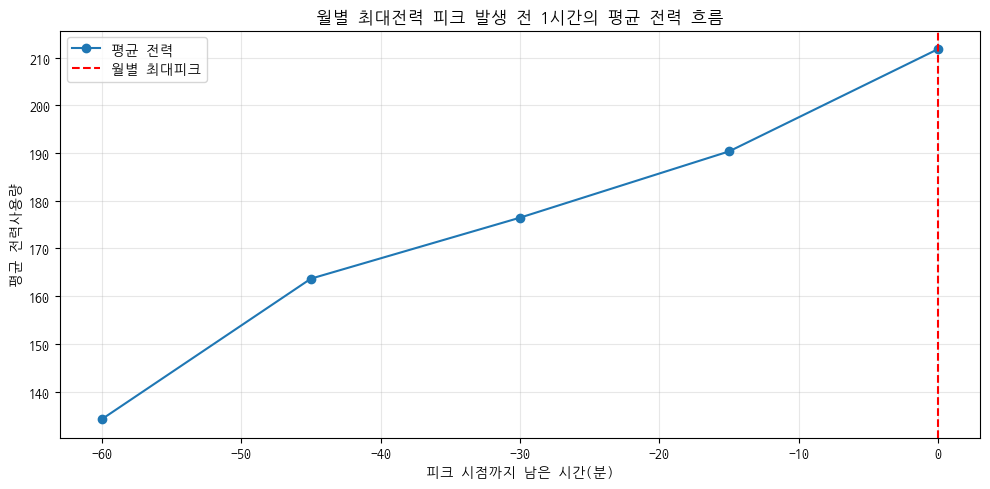

In [44]:
# ============================================================
# #43. 월별 최대피크 직전 1시간 흐름 분석
# ============================================================

peak_windows = []

for peak_number, peak_row in monthly_peak.iterrows():
    start_time = peak_row['timestamp'] - pd.Timedelta(hours=1)
    end_time = peak_row['timestamp']

    window = peak_df.loc[
        peak_df['timestamp'].between(start_time, end_time),
        ['timestamp', '전력사용량', '생산량',
         'production_change', 'operation_state']
    ].copy()

    window['피크연월'] = peak_row['연월']
    window['피크번호'] = peak_number + 1
    window['피크까지분'] = (
        (window['timestamp'] - end_time)
        .dt.total_seconds()
        .div(60)
        .astype(int)
    )
    peak_windows.append(window)

monthly_peak_windows = pd.concat(peak_windows, ignore_index=True)

pre_peak_profile = (
    monthly_peak_windows
    .groupby('피크까지분')
    .agg(
        평균전력=('전력사용량', 'mean'),
        중앙전력=('전력사용량', 'median'),
        평균생산량=('생산량', 'mean'),
        관측수=('전력사용량', 'size')
    )
    .reset_index()
    .sort_values('피크까지분')
)

display(pre_peak_profile.round(3))

plt.figure(figsize=(10, 5))
plt.plot(
    pre_peak_profile['피크까지분'],
    pre_peak_profile['평균전력'],
    marker='o',
    label='평균 전력'
)
plt.axvline(0, color='red', linestyle='--', label='월별 최대피크')
plt.xlabel('피크 시점까지 남은 시간(분)')
plt.ylabel('평균 전력사용량')
plt.title('월별 최대전력 피크 발생 전 1시간의 평균 전력 흐름')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [45]:
# ============================================================
# #44. 핵심 피크 위험조건 자동 요약
# ============================================================

def show_top_condition(table, condition_name, min_count=30):
    eligible = table.loc[table['전체관측수'] >= min_count]
    if eligible.empty:
        return f'{condition_name}: 표본 부족'

    top = eligible.sort_values('피크집중도', ascending=False).iloc[0]
    return (
        f"{condition_name}: {top.iloc[0]} | "
        f"고전력구간 내 비율 {top['피크내비율(%)']:.2f}% | "
        f"집중도 {top['피크집중도']:.2f}배 | "
        f"조건별 고전력 발생률 {top['조건별피크발생률(%)']:.2f}%"
    )


print('========== 고전력 위험조건 요약 ==========', '\n')
print(show_top_condition(high_power_hour, '시간대'))
print(show_top_condition(high_power_production, '생산량 구간'))
print(show_top_condition(high_power_change, '생산량 변화'))
print(show_top_condition(high_power_operation, '생산상태'))
print(show_top_condition(high_power_worker, '공장인원'))
print(show_top_condition(high_power_combination, '운영조건 조합'))

print('\n※ 집중도 1보다 크면 해당 조건이 전체 데이터에서 차지하는 비율보다')
print('   고전력 위험구간에서 차지하는 비율이 더 높다는 뜻입니다.')
print('※ 위 결과는 조건 간 연관성을 나타내며 직접적인 인과관계를 의미하지 않습니다.')


========== 고전력 위험조건 요약 ========== 

시간대: 9.0 | 고전력구간 내 비율 17.26% | 집중도 4.14배 | 조건별 고전력 발생률 21.79%
생산량 구간: (498.0, 1175.0] | 고전력구간 내 비율 41.91% | 집중도 2.96배 | 조건별 고전력 발생률 15.56%
생산량 변화: 생산량 증가 | 고전력구간 내 비율 8.63% | 집중도 1.10배 | 조건별 고전력 발생률 5.80%
생산상태: 생산지속 | 고전력구간 내 비율 90.14% | 집중도 1.61배 | 조건별 고전력 발생률 8.47%
공장인원: 공장인원>0 | 고전력구간 내 비율 90.45% | 집중도 1.59배 | 조건별 고전력 발생률 8.36%
운영조건 조합: 생산지속 + 생산량 변화없음 | 고전력구간 내 비율 78.04% | 집중도 1.83배 | 조건별 고전력 발생률 9.61%

※ 집중도 1보다 크면 해당 조건이 전체 데이터에서 차지하는 비율보다
   고전력 위험구간에서 차지하는 비율이 더 높다는 뜻입니다.
※ 위 결과는 조건 간 연관성을 나타내며 직접적인 인과관계를 의미하지 않습니다.


In [46]:
# ============================================================
# #45. 월별 피크 분석 결과 저장
# ============================================================

monthly_peak_name = 'monthly_max_peak_result.csv'
high_power_name = 'monthly_high_power_risk_result.csv'
peak_window_name = 'monthly_peak_previous_1hour.csv'

monthly_peak.to_csv(
    monthly_peak_name,
    index=False,
    encoding='utf-8-sig'
)
high_power_df.to_csv(
    high_power_name,
    index=False,
    encoding='utf-8-sig'
)
monthly_peak_windows.to_csv(
    peak_window_name,
    index=False,
    encoding='utf-8-sig'
)

print('저장 완료:')
print('-', monthly_peak_name, monthly_peak.shape)
print('-', high_power_name, high_power_df.shape)
print('-', peak_window_name, monthly_peak_windows.shape)

# 필요하면 아래 주석을 해제하여 다운로드
# files.download(monthly_peak_name)
# files.download(high_power_name)
# files.download(peak_window_name)


저장 완료:
- monthly_max_peak_result.csv (9, 30)
- monthly_high_power_risk_result.csv (1298, 32)
- monthly_peak_previous_1hour.csv (45, 8)


### 해석 기준

- `월별 최대피크발생수`: 해당 조건에서 월별 최댓값이 실제로 나타난 횟수입니다. 같은 월에 최댓값이 동률이면 모든 발생 시점을 포함합니다.
- `피크내비율(%)`: 월별 최대피크 발생 시점 중 해당 조건이 차지한 비율입니다.
- `피크집중도`: 피크 내 조건 비율을 전체 데이터의 조건 비율로 나눈 값입니다. 1보다 크면 월별 최대피크 또는 고전력 구간에 상대적으로 집중된 조건입니다.
- `조건별피크발생률(%)`: 해당 조건의 전체 관측 중 월별 최대피크 또는 고전력 위험구간이었던 비율입니다.

월별 최대피크 결과는 공식 피크 발생 사례를 설명할 때 사용하고, 월별 상위 5% 결과는 반복적으로 나타나는 피크 위험조건을 도출할 때 사용합니다. 두 분석에서 공통으로 높은 집중도를 보이는 조건을 최종 최대전력 피크 위험조건으로 제시하는 것이 적절합니다.


10. 고전력 경보 F1 및 영향요인·FP/FN 분석
회귀모델은 MAE·RMSE·R²로, 고전력 경보는 Precision·Recall·F1으로 평가합니다.
공식 월별 최대피크 정의는 변경하지 않습니다. 아래 이진 정답은 별도의 고전력 위험구간입니다.
기본 기준은 Train 전력의 95% 분위수이며, Test 또는 미래 월의 최댓값·분위수를 이용해 경보 기준을 정하지 않습니다.
실제값과 예측값에 동일한 기준을 적용합니다. Test에서 기준을 바꾸어 점수를 최적화하지 않습니다.
FP는 실제 일반구간인데 경보가 발생한 경우, FN은 실제 고전력인데 경보가 없는 경우입니다.
양성은 불량이나 기존 이상구간여부가 아니라 고전력입니다. 회귀값을 확률로 해석하지 않습니다.
아래 결과는 기존 Test 구간의 개발 평가입니다. 예측 대상 시점의 실제 생산량·기상정보를 입력한 경우
사전 확보 가능한 계획·예보값으로 대체하고 재평가해야 합니다. 이미 분석에 사용한 Test를 완전한 독립 검증으로 주장하지 않습니다.

In [47]:
# #46. 학습 구간에서 고전력 기준 고정
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import DMatrix
from IPython.display import display

RISK_QUANTILE = 0.95
# 실제 관리 한계가 제공되면 수치를 입력. 없으면 Train 분위수 사용.
OPERATING_LIMIT = None
alarm_limit = (float(OPERATING_LIMIT) if OPERATING_LIMIT is not None
               else float(y_train.quantile(RISK_QUANTILE)))
alarm_result = test_df.copy().reset_index(drop=True)
alarm_result['timestamp'] = (
    pd.to_datetime(alarm_result['날짜'].astype(str), format='%Y%m%d')
    + pd.to_timedelta(alarm_result['시간'], unit='h')
    + pd.to_timedelta(alarm_result['분'], unit='m'))
alarm_result['실제시각'] = alarm_result['timestamp'].dt.hour
alarm_result['실제전력'] = np.asarray(y_test)
alarm_result['예측전력'] = np.asarray(feature4_test_pred)
alarm_result['실제고전력'] = (alarm_result['실제전력'] >= alarm_limit).astype(int)
alarm_result['예측고전력'] = (alarm_result['예측전력'] >= alarm_limit).astype(int)
alarm_result['오차'] = alarm_result['실제전력'] - alarm_result['예측전력']
alarm_result['절대오차'] = alarm_result['오차'].abs()
truth = alarm_result['실제고전력'].to_numpy()
print(f'고전력 기준: {alarm_limit:.4f} (Train에서 고정)')
print('Test 양성/음성 수:', np.bincount(truth, minlength=2))
print('동률 때문에 양성비율이 정확히 5%일 필요는 없습니다.')

고전력 기준: 178.0000 (Train에서 고정)
Test 양성/음성 수: [4453  481]
동률 때문에 양성비율이 정확히 5%일 필요는 없습니다.


,방법,Precision,Recall,F1,TN,FP,FN,TP,MAE,RMSE,R2
0,Baseline XGBoost,0.7110,0.5780,0.6376,4340,113,203,278,17.5384,29.1713,0.7792
1,Persistence,0.6403,0.6403,0.6403,4280,173,173,308,7.6257,13.5048,0.9527
2,Feature4 XGBoost,0.7686,0.6216,0.6874,4363,90,182,299,5.7056,8.1987,0.9826


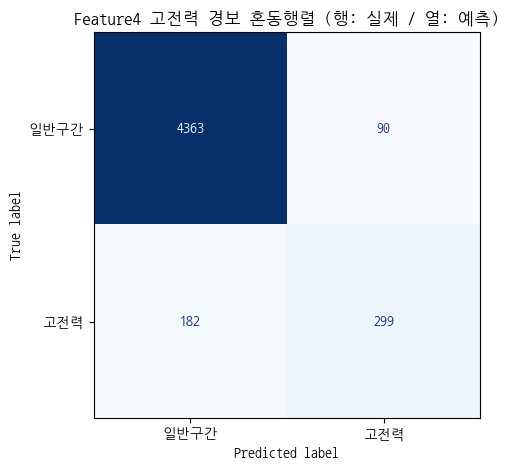

In [48]:
# #47. 동일한 정답·임계값으로 3가지 방법 비교
def alarm_metrics(y_true, predictions, limit):
    labels = (np.asarray(predictions) >= limit).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, labels, labels=[0, 1]).ravel()
    return {'Precision': precision_score(y_true, labels, zero_division=0),
            'Recall': recall_score(y_true, labels, zero_division=0),
            'F1': f1_score(y_true, labels, zero_division=0),
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

alarm_model_comparison = pd.DataFrame([
    {'방법': name, **alarm_metrics(truth, pred, alarm_limit),
     **regression_metrics(y_test, pred)}
    for name, pred in [('Baseline XGBoost', baseline_test_pred),
                       ('Persistence', persistence_pred),
                       ('Feature4 XGBoost', feature4_test_pred)]])
display(alarm_model_comparison.round(4))
ConfusionMatrixDisplay.from_predictions(
    truth, alarm_result['예측고전력'], labels=[0, 1],
    display_labels=['일반구간', '고전력'], cmap='Blues', colorbar=False)
plt.title('Feature4 고전력 경보 혼동행렬 (행: 실제 / 열: 예측)')
plt.tight_layout()
plt.show()
if truth.sum() == 0:
    print('이 Test에는 고전력 양성이 없어 F1=0을 모델 실패로 해석하면 안 됩니다.')

In [49]:
# #48. FP/FN 행 추출 및 Train 기준 생산량 구간화
actual_positive = alarm_result['실제고전력'].eq(1)
predicted_positive = alarm_result['예측고전력'].eq(1)
alarm_result['판정'] = np.select(
    [actual_positive & predicted_positive,
     ~actual_positive & predicted_positive,
     actual_positive & ~predicted_positive], ['TP', 'FP', 'FN'], default='TN')
alarm_result['FP'] = alarm_result['판정'].eq('FP').astype(int)
alarm_result['FN'] = alarm_result['판정'].eq('FN').astype(int)
alarm_result['생산량변화상태'] = np.select(
    [alarm_result['production_change'] < 0,
     alarm_result['production_change'] == 0,
     alarm_result['production_change'] > 0],
    ['감소', '유지', '증가'], default='결측')
alarm_result['인원상태'] = np.where(alarm_result['공장인원'] > 0, '인원>0', '인원=0')

train_positive_production = train_df.loc[train_df['생산량'] > 0, '생산량']
if len(train_positive_production):
    internal_edges = np.unique(train_positive_production.quantile([.25, .5, .75]).to_numpy())
else:
    internal_edges = np.array([])
alarm_production_bins = np.r_[-np.inf, internal_edges, np.inf]
alarm_result['생산량구간'] = '생산량=0'
positive_prod_mask = alarm_result['생산량'] > 0
alarm_result.loc[positive_prod_mask, '생산량구간'] = pd.cut(
    alarm_result.loc[positive_prod_mask, '생산량'],
    bins=alarm_production_bins).astype(str)
print('생산량 구간 내부 경계 (Train에서 산출):', internal_edges)
print('전체 판정:', alarm_result['판정'].value_counts().to_dict())
error_detail_columns = ['timestamp', '실제전력', '예측전력', '오차', '판정',
                        '생산량', 'production_change', 'operation_state',
                        '공장인원', 'lag_1_power', 'lag_4_power']
for error_type in ['FN', 'FP']:
    print(f'{error_type} 사례 (절대오차 큰 순서, 최대 20건)')
    display(alarm_result.loc[alarm_result['판정'].eq(error_type)]
            .sort_values('절대오차', ascending=False)[error_detail_columns].head(20))

생산량 구간 내부 경계 (Train에서 산출): [ 112.  489. 1142.]
전체 판정: {'TN': 4363, 'TP': 299, 'FN': 182, 'FP': 90}
FN 사례 (절대오차 큰 순서, 최대 20건)


,timestamp,실제전력,예측전력,오차,판정,생산량,production_change,operation_state,공장인원,lag_1_power,lag_4_power
3078,2021-08-26 16:15:00,186,154.142868,31.857132,FN,645,-1389.0,생산지속,0.933430,193.0,163.0
1638,2021-08-11 16:15:00,185,153.391983,31.608017,FN,330,-1404.0,생산지속,0.453920,164.0,131.0
3826,2021-09-03 11:15:00,187,156.594223,30.405777,FN,337,-180.0,생산지속,0.451138,169.0,148.0
1426,2021-08-09 11:15:00,192,162.649445,29.350555,FN,1431,1023.0,생산지속,1.910547,173.0,167.0
1822,2021-08-13 14:15:00,200,171.213882,28.786118,FN,1512,119.0,생산지속,1.997358,182.0,162.0
1807,2021-08-13 10:30:00,201,172.287186,28.712814,FN,1023,0.0,생산지속,1.393733,151.0,191.0
4111,2021-09-06 10:30:00,190,162.935059,27.064941,FN,615,0.0,생산지속,0.900439,144.0,148.0
4493,2021-09-10 10:00:00,204,176.944351,27.055649,FN,1038,0.0,생산지속,1.410326,179.0,192.0
3838,2021-09-03 14:15:00,178,151.001678,26.998322,FN,280,-960.0,생산지속,0.392707,176.0,155.0
3742,2021-09-02 14:15:00,195,168.717575,26.282425,FN,1151,-228.0,생산지속,1.498698,183.0,168.0


FP 사례 (절대오차 큰 순서, 최대 20건)


,timestamp,실제전력,예측전력,오차,판정,생산량,production_change,operation_state,공장인원,lag_1_power,lag_4_power
2963,2021-08-25 11:30:00,158,182.439362,-24.439362,FP,1409,0.0,생산지속,2.036127,172.0,179.0
3539,2021-08-31 11:30:00,159,182.252640,-23.252640,FP,1255,0.0,생산지속,1.904401,182.0,187.0
3434,2021-08-30 09:15:00,167,189.422043,-22.422043,FP,1343,464.0,생산지속,1.977909,183.0,133.0
3444,2021-08-30 11:45:00,161,183.026138,-22.026138,FP,766,0.0,생산지속,1.118248,178.0,186.0
3529,2021-08-31 09:00:00,157,178.226486,-21.226486,FP,653,0.0,생산지속,0.977545,175.0,143.0
2763,2021-08-23 09:30:00,165,186.098236,-21.098236,FP,1105,0.0,생산지속,1.536857,187.0,163.0
2377,2021-08-19 09:00:00,159,178.883240,-19.883240,FP,670,0.0,생산지속,0.964029,177.0,143.0
2860,2021-08-24 09:45:00,170,189.250488,-19.250488,FP,516,0.0,생산지속,0.713693,190.0,196.0
3441,2021-08-30 11:00:00,165,183.251740,-18.251740,FP,844,0.0,생산지속,1.232117,186.0,174.0
4202,2021-09-07 09:15:00,168,185.447617,-17.447617,FP,1727,491.0,생산지속,2.543446,192.0,153.0


In [50]:
# #49. 공정조건별 오류 수 + 적절한 분모의 오류율
# FN율 = FN / 실제고전력수; FP율 = FP / 실제일반수
# 건수가 많은 조건과 실제 실패확률이 높은 조건을 구분합니다.
MIN_CONDITION_ROWS = 30
MIN_CLASS_ROWS = 10
def error_condition_table(data, columns):
    keys = [columns] if isinstance(columns, str) else list(columns)
    rows = []
    base_fn_rate = data['FN'].sum() / data['실제고전력'].sum() if data['실제고전력'].sum() else np.nan
    base_fp_rate = data['FP'].sum() / data['실제고전력'].eq(0).sum() if data['실제고전력'].eq(0).sum() else np.nan
    for key, group in data.groupby(keys, dropna=False, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        n = len(group)
        pos = int(group['실제고전력'].sum())
        neg = n - pos
        fn = int(group['FN'].sum()); fp = int(group['FP'].sum())
        fn_rate = fn / pos if pos else np.nan
        fp_rate = fp / neg if neg else np.nan
        rows.append({**dict(zip(keys, key)), '관측수': n, '실제고전력수': pos,
                     '실제일반수': neg, 'FN수': fn, 'FP수': fp,
                     'FN율(%)': fn_rate * 100, 'FP율(%)': fp_rate * 100,
                     'FN전체대비율': fn_rate / base_fn_rate if base_fn_rate > 0 else np.nan,
                     'FP전체대비율': fp_rate / base_fp_rate if base_fp_rate > 0 else np.nan,
                     'FN해석표본충족': n >= MIN_CONDITION_ROWS and pos >= MIN_CLASS_ROWS,
                     'FP해석표본충족': n >= MIN_CONDITION_ROWS and neg >= MIN_CLASS_ROWS,
                     'MAE': group['절대오차'].mean()})
    return pd.DataFrame(rows)

condition_error_tables = {}
for column in ['실제시각', '생산량구간', '생산량변화상태', 'operation_state', '인원상태']:
    table = error_condition_table(alarm_result, column)
    condition_error_tables[column] = table
    print(f'조건: {column}')
    display(table.sort_values(['FN율(%)', 'FP율(%)'], ascending=False).round(4))
print('NaN 오류율: 해당 조건에 실제 양성/음성이 없어 분모가 0인 경우')
print('표본충족은 간단한 해석 가이드이며 통계적 유의성 검정이 아닙니다.')

조건: 실제시각


,실제시각,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
19,19,208,6,202,6,0,100.0000,0.0000,2.6429,0.0000,False,True,6.8379
18,18,208,16,192,13,4,81.2500,2.0833,2.1473,1.0308,True,True,6.4722
17,17,208,4,204,3,1,75.0000,0.4902,1.9821,0.2425,False,True,7.8715
16,16,208,41,167,25,7,60.9756,4.1916,1.6115,2.0739,True,True,6.6711
15,15,208,38,170,20,5,52.6316,2.9412,1.3910,1.4552,True,True,7.2680
10,10,204,58,146,25,7,43.1034,4.7945,1.1392,2.3722,True,True,6.7615
13,13,204,37,167,14,9,37.8378,5.3892,1.0000,2.6665,True,True,6.6205
14,14,205,70,135,26,15,37.1429,11.1111,0.9816,5.4975,True,True,6.7682
12,12,204,22,182,6,2,27.2727,1.0989,0.7208,0.5437,True,True,6.8402
11,11,204,74,130,20,14,27.0270,10.7692,0.7143,5.3284,True,True,6.3667


조건: 생산량구간


,생산량구간,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
4,생산량=0,2062,4,2058,3,1,75.0000,0.0486,1.9821,0.0240,False,True,3.4433
1,"(112.0, 489.0]",780,37,743,19,9,51.3514,1.2113,1.3571,0.5993,True,True,6.3846
3,"(489.0, 1142.0]",644,183,461,67,36,36.6120,7.8091,0.9676,3.8638,True,True,8.0675
2,"(1142.0, inf]",832,257,575,93,44,36.1868,7.6522,0.9564,3.7861,True,True,8.4987
0,"(-inf, 112.0]",616,0,616,0,0,NaN,0.0000,NaN,0.0000,False,True,6.1764


조건: 생산량변화상태


...

조건: operation_state


,operation_state,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
1,생산시작,34,1,33,1,0,100.000,0.0000,2.6429,0.0000,False,True,8.5722
0,비생산지속,2029,4,2025,3,1,75.000,0.0494,1.9821,0.0244,False,True,3.3760
3,생산지속,2838,476,2362,178,89,37.395,3.7680,0.9883,1.8643,True,True,7.3149
2,생산종료전환,33,0,33,0,0,NaN,0.0000,NaN,0.0000,False,True,7.5851


조건: 인원상태


,인원상태,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
0,인원=0,2062,4,2058,3,1,75.0000,0.0486,1.9821,0.0240,False,True,3.4433
1,인원>0,2872,477,2395,179,89,37.5262,3.7161,0.9918,1.8386,True,True,7.3298


NaN 오류율: 해당 조건에 실제 양성/음성이 없어 분모가 0인 경우
표본충족은 간단한 해석 가이드이며 통계적 유의성 검정이 아닙니다.


In [51]:
# #50. 조건 조합별 FP/FN: 상호작용의 운영상 해석
combination_error_tables = {}
for columns in [('실제시각', '생산량구간'),
                ('operation_state', '생산량변화상태'),
                ('실제시각', 'operation_state')]:
    name = ' + '.join(columns)
    table = error_condition_table(alarm_result, columns)
    combination_error_tables[name] = table
    print(name)
    display(table.sort_values('FN수', ascending=False).round(4).head(20))
    for flag, metric in [('FN해석표본충족', 'FN율(%)'), ('FP해석표본충족', 'FP율(%)')]:
        print('표본조건 충족 그룹의', metric, '상위 5개')
        display(table.loc[table[flag]].sort_values(metric, ascending=False).head(5).round(4))
print('조합별 오류율은 연관성 분석입니다. 설비별 원인 또는 인과관계를 입증하지 않습니다.')

실제시각 + 생산량구간


,실제시각,생산량구간,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
65,14,"(1142.0, inf]",96,51,45,19,13,37.2549,28.8889,0.9846,14.2936,True,True,8.8460
48,10,"(489.0, 1142.0]",68,34,34,15,5,44.1176,14.7059,1.1660,7.2761,True,True,7.6812
51,11,"(1142.0, inf]",78,43,35,13,7,30.2326,20.0000,0.7990,9.8956,True,True,7.8536
73,16,"(1142.0, inf]",87,24,63,13,5,54.1667,7.9365,1.4315,3.9268,True,True,8.1766
61,13,"(1142.0, inf]",75,31,44,11,5,35.4839,11.3636,0.9378,5.6225,True,True,8.1035
69,15,"(1142.0, inf]",78,24,54,10,3,41.6667,5.5556,1.1012,2.7488,True,True,10.0572
74,16,"(489.0, 1142.0]",33,14,19,10,0,71.4286,0.0000,1.8878,0.0000,True,True,9.1021
47,10,"(1142.0, inf]",51,18,33,9,2,50.0000,6.0606,1.3214,2.9987,True,True,10.1101
43,9,"(1142.0, inf]",51,31,20,6,5,19.3548,25.0000,0.5115,12.3694,True,True,7.8445
38,8,"(112.0, 489.0]",23,9,14,6,2,66.6667,14.2857,1.7619,7.0683,False,False,10.1353


표본조건 충족 그룹의 FN율(%) 상위 5개


,실제시각,생산량구간,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
74,16,"(489.0, 1142.0]",33,14,19,10,0,71.4286,0.0000,1.8878,0.0000,True,True,9.1021
70,15,"(489.0, 1142.0]",43,10,33,6,2,60.0000,6.0606,1.5857,2.9987,True,True,9.3196
73,16,"(1142.0, inf]",87,24,63,13,5,54.1667,7.9365,1.4315,3.9268,True,True,8.1766
47,10,"(1142.0, inf]",51,18,33,9,2,50.0000,6.0606,1.3214,2.9987,True,True,10.1101
48,10,"(489.0, 1142.0]",68,34,34,15,5,44.1176,14.7059,1.1660,7.2761,True,True,7.6812


표본조건 충족 그룹의 FP율(%) 상위 5개


...

표본조건 충족 그룹의 FN율(%) 상위 5개


,실제시각,operation_state,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
53,18,생산지속,119,13,106,11,3,84.6154,2.8302,2.2363,1.4003,True,True,7.5709
46,16,생산지속,128,41,87,25,7,60.9756,8.0460,1.6115,3.9810,True,True,8.7424
44,15,생산지속,128,38,90,20,5,52.6316,5.5556,1.3910,2.7488,True,True,9.9143
32,10,생산지속,128,58,70,25,7,43.1034,10.0000,1.1392,4.9478,True,True,8.8055
42,14,생산지속,128,70,58,26,15,37.1429,25.8621,0.9816,12.7960,True,True,8.8698


표본조건 충족 그룹의 FP율(%) 상위 5개


,실제시각,operation_state,관측수,실제고전력수,실제일반수,FN수,FP수,FN율(%),FP율(%),FN전체대비율,FP전체대비율,FN해석표본충족,FP해석표본충족,MAE
30,9,생산지속,128,69,59,13,17,18.8406,28.8136,0.4979,14.2563,True,True,7.7294
34,11,생산지속,128,74,54,20,14,27.0270,25.9259,0.7143,12.8276,True,True,7.9874
42,14,생산지속,128,70,58,26,15,37.1429,25.8621,0.9816,12.7960,True,True,8.8698
28,8,생산지속,125,46,79,11,9,23.9130,11.3924,0.6320,5.6367,True,True,7.2662
40,13,생산지속,118,36,82,13,9,36.1111,10.9756,0.9544,5.4305,True,True,8.5928


조합별 오류율은 연관성 분석입니다. 설비별 원인 또는 인과관계를 입증하지 않습니다.


,변수,평균절대SHAP,평균SHAP
13,lag_1_power,45.118599,-4.3902
14,lag_4_power,3.834400,0.5834
2,생산량,3.748300,0.5418
0,시간,3.417500,0.1887
1,분,1.736800,-0.0777
11,공장인원,1.725400,-0.1488
12,인건비,1.413900,0.2251
8,day,0.792400,0.2362
10,m,0.636000,0.1877
7,전기요금(계절),0.623200,0.4207


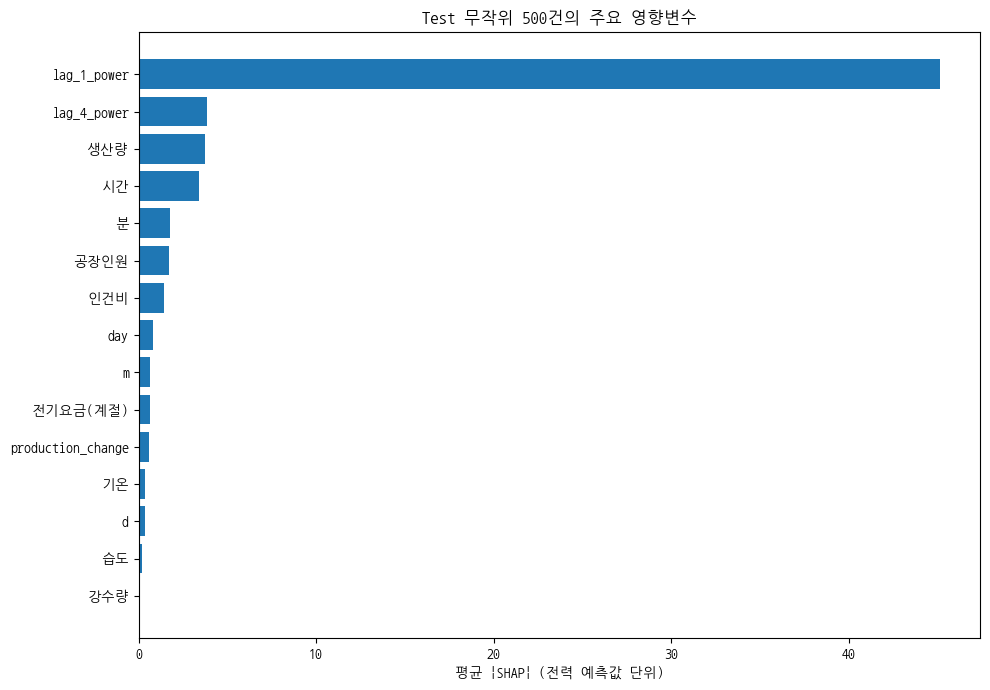

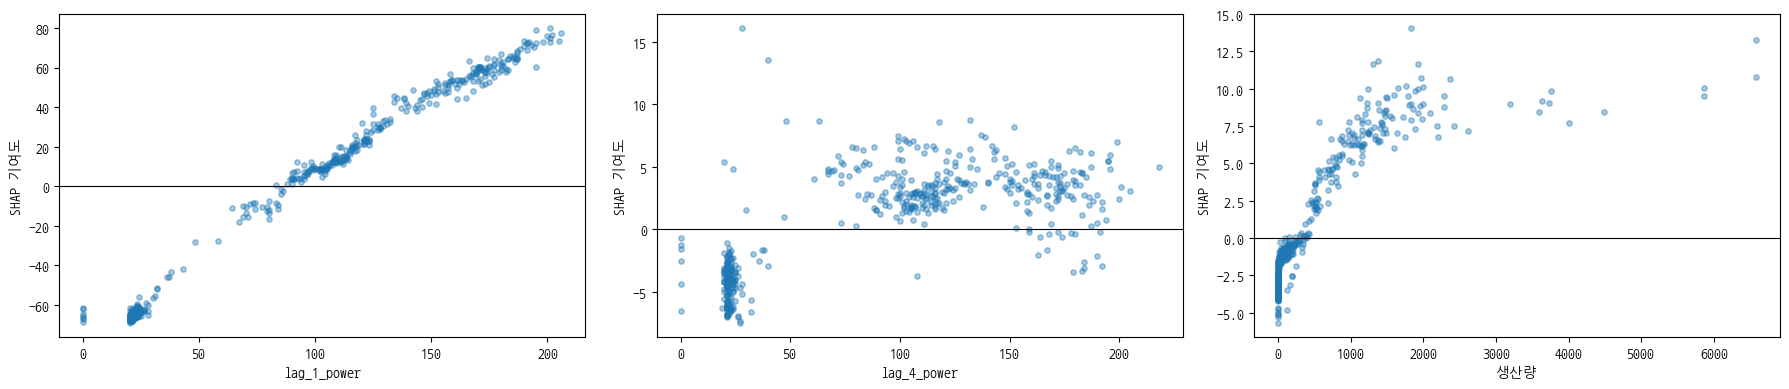

양의 SHAP: 기준 예측에서 전력을 높임 / 음의 SHAP: 낮춤
평균SHAP은 양·음이 상쇄됩니다. 중요도 순위는 평균절대SHAP을 봅니다.


In [52]:
# #51. XGBoost 내장 TreeSHAP: 주요 영향변수와 방향
# 별도의 shap 패키지가 필요하지 않습니다.
# 예측 기여도를 해석하며, 원인이나 변수 제거 시 성능저하와는 다릅니다.
SHAP_SAMPLE_SIZE = 500
sample_size = min(SHAP_SAMPLE_SIZE, len(X_test_feature4))
sample_positions = np.sort(np.random.default_rng(42).choice(
    len(X_test_feature4), size=sample_size, replace=False))
shap_X = X_test_feature4.iloc[sample_positions].copy()
booster = feature4_model.get_booster()
shap_matrix = booster.predict(DMatrix(shap_X), pred_contribs=True)
shap_values = shap_matrix[:, :-1]
shap_bias = shap_matrix[:, -1]
sample_predictions = feature4_model.predict(shap_X)
assert np.allclose(shap_values.sum(axis=1) + shap_bias,
                   sample_predictions, atol=1e-3, rtol=1e-4)
shap_importance = pd.DataFrame({
    '변수': shap_X.columns,
    '평균절대SHAP': np.abs(shap_values).mean(axis=0),
    '평균SHAP': shap_values.mean(axis=0)
}).sort_values('평균절대SHAP', ascending=False)
display(shap_importance.round(4))
plt.figure(figsize=(10, 7))
plot_imp = shap_importance.head(15).sort_values('평균절대SHAP')
plt.barh(plot_imp['변수'], plot_imp['평균절대SHAP'])
plt.xlabel('평균 |SHAP| (전력 예측값 단위)')
plt.title(f'Test 무작위 {sample_size}건의 주요 영향변수')
plt.tight_layout(); plt.show()

top_names = shap_importance['변수'].head(3).tolist()
fig, axes = plt.subplots(1, len(top_names), figsize=(6 * len(top_names), 4))
for ax, name in zip(np.atleast_1d(axes), top_names):
    j = shap_X.columns.get_loc(name)
    ax.scatter(shap_X[name], shap_values[:, j], alpha=.4, s=15)
    ax.axhline(0, color='black', linewidth=.8)
    ax.set_xlabel(name); ax.set_ylabel('SHAP 기여도')
plt.tight_layout(); plt.show()
print('양의 SHAP: 기준 예측에서 전력을 높임 / 음의 SHAP: 낮춤')
print('평균SHAP은 양·음이 상쇄됩니다. 중요도 순위는 평균절대SHAP을 봅니다.')

,변수A,변수B,평균절대쌍상호작용
0,lag_1_power,lag_4_power,6.7035
1,시간,lag_1_power,1.9154
2,분,lag_1_power,1.3539
3,시간,lag_4_power,1.3266
4,인건비,lag_1_power,1.2970
5,분,lag_4_power,1.2569
6,인건비,lag_4_power,1.1263
7,시간,생산량,0.8738
8,생산량,공장인원,0.8189
9,시간,분,0.8152


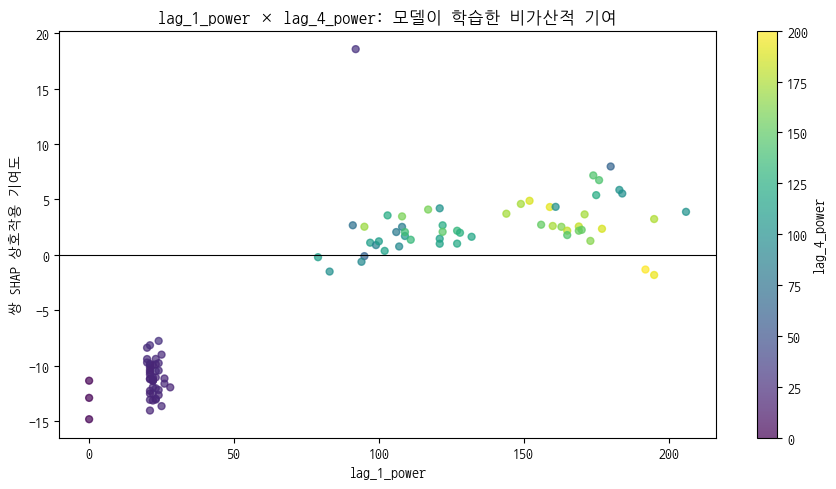

대각항(주효과)은 제외. 상호작용 크기는 상관계수나 인과효과가 아닙니다.


In [53]:
# #52. TreeSHAP 상호작용: 변수 A의 영향이 B에 따라 달라지는 조합
INTERACTION_SAMPLE_SIZE = 100  # 계산시간이 길면 50으로 줄일 수 있음
interaction_X = shap_X.sample(n=min(INTERACTION_SAMPLE_SIZE, len(shap_X)), random_state=42)
interaction_values = booster.predict(DMatrix(interaction_X), pred_interactions=True)
mean_abs_interaction = np.abs(interaction_values[:, :-1, :-1]).mean(axis=0)
pair_rows = []
names = interaction_X.columns.tolist()
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        # 대칭인 두 비대각항을 합친 쌍 기여도 규모
        pair_rows.append({'변수A': names[i], '변수B': names[j],
                          '평균절대쌍상호작용': 2 * mean_abs_interaction[i, j]})
shap_interaction_table = pd.DataFrame(pair_rows).sort_values(
    '평균절대쌍상호작용', ascending=False).reset_index(drop=True)
display(shap_interaction_table.head(15).round(4))

best_pair = shap_interaction_table.iloc[0]
a, b = best_pair['변수A'], best_pair['변수B']
ia, ib = names.index(a), names.index(b)
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(interaction_X[a],
                2 * interaction_values[:, ia, ib],
                c=interaction_X[b], cmap='viridis', s=25, alpha=.7)
fig.colorbar(sc, ax=ax, label=b)
ax.axhline(0, color='black', linewidth=.8)
ax.set_xlabel(a); ax.set_ylabel('쌍 SHAP 상호작용 기여도')
ax.set_title(f'{a} × {b}: 모델이 학습한 비가산적 기여')
plt.tight_layout(); plt.show()
print('대각항(주효과)은 제외. 상호작용 크기는 상관계수나 인과효과가 아닙니다.')

In [54]:
# #53. FP/FN 사례에서 모델이 어떤 변수를 활용했는지
error_shap_profiles = []
for kind in ['TP', 'FN', 'FP', 'TN']:
    positions = np.flatnonzero(alarm_result['판정'].eq(kind).to_numpy())
    if not len(positions):
        print(kind, '사례가 없습니다.'); continue
    # 오류가 많은 경우 계산량 제한, 무작위 추출
    positions = np.sort(np.random.default_rng(42).choice(
        positions, size=min(200, len(positions)), replace=False))
    values = booster.predict(DMatrix(X_test_feature4.iloc[positions]),
                             pred_contribs=True)[:, :-1]
    profile = pd.DataFrame({'판정': kind, '변수': X_test_feature4.columns,
                            '분석표본수': len(positions),
                            '평균SHAP': values.mean(axis=0),
                            '평균절대SHAP': np.abs(values).mean(axis=0)})
    error_shap_profiles.append(profile)
    print(kind, '예측 기여도 상위 변수')
    display(profile.sort_values('평균절대SHAP', ascending=False).head(8).round(4))
error_shap_profile = (pd.concat(error_shap_profiles, ignore_index=True)
                      if error_shap_profiles else pd.DataFrame())
print('FN/FP SHAP는 예측 형성을 설명합니다. 실제 오차의 원인을 확정하지 않습니다.')

TP 예측 기여도 상위 변수


,판정,변수,분석표본수,평균SHAP,평균절대SHAP
13,TP,lag_1_power,200,69.290199,69.290199
2,TP,생산량,200,6.856600,6.903900
0,TP,시간,200,6.261700,6.263700
14,TP,lag_4_power,200,4.540900,4.544900
1,TP,분,200,1.319000,2.679400
12,TP,인건비,200,1.702400,1.863000
11,TP,공장인원,200,-0.970700,1.857400
10,TP,m,200,1.208800,1.210500


FN 예측 기여도 상위 변수


,판정,변수,분석표본수,평균SHAP,평균절대SHAP
13,FN,lag_1_power,182,57.052399,57.052399
2,FN,생산량,182,6.661500,6.853900
0,FN,시간,182,5.754300,5.808200
14,FN,lag_4_power,182,4.021600,4.050400
1,FN,분,182,0.821000,2.975200
11,FN,공장인원,182,-1.627200,2.405900
12,FN,인건비,182,1.788400,1.912800
10,FN,m,182,1.177100,1.177100


FP 예측 기여도 상위 변수


,판정,변수,분석표본수,평균SHAP,평균절대SHAP
13,FP,lag_1_power,90,65.2202,65.2202
2,FP,생산량,90,6.4775,6.5542
0,FP,시간,90,5.8297,5.8399
14,FP,lag_4_power,90,5.0147,5.0147
11,FP,공장인원,90,-1.4040,2.3278
1,FP,분,90,1.3370,2.1556
12,FP,인건비,90,1.6235,1.7706
10,FP,m,90,1.1925,1.1925


TN 예측 기여도 상위 변수


,판정,변수,분석표본수,평균SHAP,평균절대SHAP
13,TN,lag_1_power,200,-15.1251,44.146099
14,TN,lag_4_power,200,-0.1443,3.835100
2,TN,생산량,200,-0.3797,3.347000
0,TN,시간,200,-0.2739,3.141400
11,TN,공장인원,200,0.0170,1.665500
1,TN,분,200,-0.1167,1.607500
12,TN,인건비,200,0.2244,1.441700
8,TN,day,200,0.1903,0.744700


FN/FP SHAP는 예측 형성을 설명합니다. 실제 오차의 원인을 확정하지 않습니다.


In [55]:
# #54. 공식 월별 최대피크의 경보 누락 여부 (고전력 F1과 별개)
# Test가 포함된 월에서도 공식 피크는 df_feature4 전체 월 관측으로 판정합니다.
peak_reference = df_feature4.copy()
peak_reference['timestamp'] = (
    pd.to_datetime(peak_reference['날짜'].astype(str), format='%Y%m%d')
    + pd.to_timedelta(peak_reference['시간'], unit='h')
    + pd.to_timedelta(peak_reference['분'], unit='m'))
peak_reference['연월'] = pd.to_datetime(
    peak_reference['날짜'].astype(str), format='%Y%m%d').dt.to_period('M').astype(str)
peak_reference['월별최대피크여부'] = peak_reference['전력사용량'].eq(
    peak_reference.groupby('연월')['전력사용량'].transform('max'))
if peak_reference['timestamp'].duplicated().any():
    raise ValueError('timestamp 중복: 조인 전 중복 관측을 확인하세요.')
monthly_peak_alarm = alarm_result.merge(
    peak_reference.loc[peak_reference['월별최대피크여부'], ['timestamp', '연월']],
    on='timestamp', how='inner', validate='one_to_one')
print('Test에 포함된 공식 월별 최대피크의 경보 결과')
display(monthly_peak_alarm[['연월'] + error_detail_columns])
print('고전력 기준이 월별 최대값보다 높으면 공식 피크라도 실제고전력=0일 수 있습니다.')
print('이는 서로 다른 정의이며, 월별 최대피크 포착 여부를 별도로 해석합니다.')
print('관측이 불완전한 월의 최대값은 제공된 관측 범위의 최대값입니다. 전체 달의 최대값으로 단정하지 않습니다.')

Test에 포함된 공식 월별 최대피크의 경보 결과


,연월,timestamp,실제전력,예측전력,오차,판정,생산량,production_change,operation_state,공장인원,lag_1_power,lag_4_power
0,2021-08,2021-08-11 08:45:00,218,197.914871,20.085129,TP,783,0.0,생산지속,0.964286,206.0,142.0
1,2021-09,2021-09-10 10:00:00,204,176.944351,27.055649,FN,1038,0.0,생산지속,1.410326,179.0,192.0


고전력 기준이 월별 최대값보다 높으면 공식 피크라도 실제고전력=0일 수 있습니다.
이는 서로 다른 정의이며, 월별 최대피크 포착 여부를 별도로 해석합니다.
관측이 불완전한 월의 최대값은 제공된 관측 범위의 최대값입니다. 전체 달의 최대값으로 단정하지 않습니다.


In [56]:
# #55. 분석 결과 저장: Colab 현재 폴더에 생성
analysis_exports = {
    'peak_alarm_model_comparison.csv': alarm_model_comparison,
    'peak_alarm_test_results.csv': alarm_result,
    'peak_alarm_FN_cases.csv': alarm_result.loc[alarm_result['판정'].eq('FN')],
    'peak_alarm_FP_cases.csv': alarm_result.loc[alarm_result['판정'].eq('FP')],
    'peak_alarm_condition_errors.csv': pd.concat(
        [table.assign(분석조건=name) for name, table in condition_error_tables.items()],
        ignore_index=True),
    'peak_alarm_combination_errors.csv': pd.concat(
        [table.assign(분석조건=name) for name, table in combination_error_tables.items()],
        ignore_index=True),
    'power_SHAP_importance.csv': shap_importance,
    'power_SHAP_interactions.csv': shap_interaction_table,
    'peak_alarm_error_SHAP.csv': error_shap_profile,
    'monthly_max_peak_alarm_results.csv': monthly_peak_alarm,
}
for filename, table in analysis_exports.items():
    table.to_csv(filename, index=False, encoding='utf-8-sig')
    print(filename, table.shape)
# 개별 다운로드 예시: files.download('peak_alarm_model_comparison.csv')

peak_alarm_model_comparison.csv (3, 11)
peak_alarm_test_results.csv (4934, 35)
peak_alarm_FN_cases.csv (182, 35)
peak_alarm_FP_cases.csv (90, 35)
peak_alarm_condition_errors.csv (38, 18)
peak_alarm_combination_errors.csv (185, 17)
power_SHAP_importance.csv (20, 3)
power_SHAP_interactions.csv (190, 3)
peak_alarm_error_SHAP.csv (80, 5)
monthly_max_peak_alarm_results.csv (2, 36)


보고서 해석 순서
1. #47: 세 방법의 MAE·RMSE·R²와 고전력 Precision·Recall·F1을 함께 비교합니다.
2. #49~50: FN수/FP수와 각 클래스 분모 기준의 FN율/FP율을 함께 보고 표본이 부족한 조건을 표시합니다.
3. #51: 평균절대SHAP으로 주요 변수를, 의존도 그림으로 영향 방향과 비선형 관계를 확인합니다.
4. #52: 상호작용 순위와 그림을 보고 #50의 공정조건 조합 결과와 연결합니다.
5. #54: 월별 최대피크에서 경보가 실제 발생했는지 별도로 확인합니다.
F1은 고전력 위험구간 탐지 점수이며 전력 회귀 정확도나 월별 최대값 예측의 F1로 표현하지 않습니다.
FN은 피크 대비 미흡, FP는 불필요한 경보라는 운영 의미를 가집니다.
현재 그림의 공통 평가표에 나온 제조 불량·확률 예측 문구는 과제⑤의 전력 예측과 직접 동일하지 않습니다.
주최 측 과제별 평가 안내에서 확률 출력이 요구되는지 별도 확인할 수 있으며, 현재 결과를 불량 확률로 주장하지 않습니다.
제공 데이터 실행 검증 참고값
기존 80:20 시간순 분할과 기존 모델 설정으로 검증했습니다. 고전력 기준은 Train 95% 분위수인 178입니다.
이는 업무상 확정된 관리 한계가 아니라 분석용 기준이며, 데이터·버전·기준이 바뀌면 재계산해야 합니다.
방법	Precision	Recall	F1	FP	FN
Baseline XGBoost	0.7110	0.5780	0.6376	113	203
Persistence	0.6403	0.6403	0.6403	173	173
Feature4 XGBoost	0.7686	0.6216	0.6874	90	182


Feature4는 F1과 Precision이 높지만 Recall은 Persistence보다 낮습니다.
즉 오경보는 줄였으나 고전력 누락까지 모든 지표에서 개선된 것은 아닙니다.
Feature4의 R²=0.9826만으로 피크 경보가 충분하다고 결론내리면 안 됩니다.
다음 개선은 별도 시간순 검증 구간에서 FN·FP 비용을 정하고 경보 임계값을 선택한 후,
손대지 않은 최종 평가 구간에서 재검증하는 것입니다. Test에서 임계값을 최적화하지 않습니다.
무작위 Test 500건의 평균절대SHAP 상위 변수는 직전 전력, 1시간 전 전력, 생산량, 시간, 분입니다.
상호작용은 별도 무작위 100건 기준이며 표본 크기를 늘려 순위 안정성을 확인할 수 있습니다.
두 전력 시차의 상호작용은 최근 전력 흐름을 결합해 활용한다는 모델 해석이지,
설비 동시 가동의 인과 증거는 아닙니다.